<h1 style='font-weight:bold; color:#003366; text-align:center;'>Proyecto Final B: Arroyo Capital</h1>

<h3 style='font-weight:bold; color:#003366; text-align:center;'>Tesis de inversión y portafolio en la industria del cine</h3>
<h4 style='font-weight:bold; color:#003366; text-align:center;'>Programación Analítica II · Universidad de Montevideo · S2 2026</h4>
<h4 style='font-weight:bold; color:#003366; text-align:center;'>Docente Camila Palomeque</h4>
<h4 style='font-weight:bold; color:#003366; text-align:center;'>Santiago de la Vega y Geronimo Orihuela</h4>

## Objetivo y cómo se lee este notebook

Arroyo Capital va a colocar USD 500 millones en producción cinematográfica durante tres años y nadie
en el fondo invirtió nunca en cine. El Chief Investment Officer no pide adivinar qué película va a funcionar:
pide saber qué clase de película tiene mejor relación entre riesgo y retorno, y cuánto se puede perder.

El notebook sigue las cinco etapas de la letra y corre de arriba abajo sin intervención:

1. Auditoría y limpieza de datos (cada cambio queda registrado en una bitácora con el porcentaje de la base afectado).
2. Creación de variables (dólares constantes, retorno y regla del 2,5×).
3. Análisis de negocio (crecimiento, retorno por segmento, riesgo).
4. Visualizaciones (incluye un gráfico interactivo con Plotly).
5. Tesis de inversión (arquetipos, asignación de los USD 500 M, retorno por ventanas históricas y prueba fuera de muestra).

**Convenciones.** Los montos están en USD. *Corrientes* = del año de estreno; *constantes* = dólares de 2020.
El retorno (o ROI en esta letra) es la recaudación mundial dividida por el presupuesto de producción,
es decir un múltiplo: 2,5 significa que la película recaudó 2,5 veces lo que costó. Una película
**recupera** la inversión si ese múltiplo es de 2,5 o más (regla de la industria).

<h2 style='font-weight:bold; color:#003366;'>0. Configuración</h2>

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
from IPython.display import display

# ---- Constantes del análisis (cada una con su razón) ----
ANIO_BASE = 2020  # año cuyos dólares usamos como "constantes"
UMBRAL_RECUPERO = 2.5  # regla de la industria: recaudación >= 2,5 x presupuesto
# Umbral estricto: el exhibidor se queda con 50% de la boletería y el marketing
# cuesta ~75% del presupuesto (punto medio de 50%-100%). Para que el estudio
# recupere todo: 0,5 x recaudación = 1,75 x presupuesto, o sea 3,5 x.
PARTE_ESTUDIO = 0.5  # fracción de la boletería que no se queda el exhibidor
MARKETING_SOBRE_PRESUPUESTO = 0.75
UMBRAL_ESTRICTO = (1 + MARKETING_SOBRE_PRESUPUESTO) / PARTE_ESTUDIO  # = 3,5
ANIO_CORTE = 2014  # criterios con películas hasta 2014, prueba 2015-2020
MIN_PELICULAS = 30  # un segmento con menos películas no se interpreta
PRESUPUESTO_FONDO = 500e6  # USD 500 millones a colocar
VENTANA_ANIOS = 3  # el fondo coloca la plata en tres años: se mira cada ventana de tres años
MIN_VENTANA = 5  # películas mínimas de un arquetipo en una ventana para calcular su mediana

pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")


def ruta_datos(nombre_archivo):
    """Busca el archivo en las ubicaciones habituales del repo (y de Colab)."""
    candidatas = [
        Path("../datos") / nombre_archivo,
        Path("datos") / nombre_archivo,
        Path("/content/datos") / nombre_archivo,
        Path(nombre_archivo),
    ]
    for candidata in candidatas:
        if candidata.exists():
            return candidata
    raise FileNotFoundError(f"No encuentro {nombre_archivo}. Revisá la carpeta datos/.")


CARPETA_SALIDAS = ruta_datos("peliculas.csv").parent.parent / "salidas"
CARPETA_SALIDAS.mkdir(exist_ok=True)


def guardar_figura(figura, nombre):
    """Guarda la figura en salidas/ para poder usarla en la presentación."""
    figura.savefig(CARPETA_SALIDAS / f"{nombre}.png", dpi=150, bbox_inches="tight")

<h2 style='font-weight:bold; color:#003366;'>Etapa 1: Análisis exploratorio y correcciones de calidad</h2>

<h3 style='font-weight:bold; color:#0033BB;'>1.1 Carga de los archivos</h3>

Los tipos se declaran al cargar. Una excepción deliberada: `fecha_estreno` entra como texto, porque
la columna mezcla dos formatos (`2010-07-01` y `16/11/1988`) y `parse_dates` no puede resolver los dos a la vez.
Se parsea después, con una función que prueba cada formato.

In [2]:
TIPOS_PELICULAS = {
    "id_pelicula": "int64",
    "titulo": "string",
    "anio_estreno": "int64",
    "fecha_estreno": "string",
    "genero": "string",
    "clasificacion": "string",
    "pais_origen": "string",
    "es_secuela": "string",
    "director": "string",
    "guionista": "string",
    "protagonista": "string",
    "productora": "string",
    "duracion_minutos": "float64",
    "puntaje_imdb": "float64",
    "cantidad_votos": "float64",
    "presupuesto_usd": "float64",
    "recaudacion_mundial_usd": "float64",
}

peliculas_crudo = pd.read_csv(ruta_datos("peliculas.csv"), dtype=TIPOS_PELICULAS)
ipc = pd.read_csv(ruta_datos("ipc_eeuu.csv"), dtype={"anio": "int64", "ipc_eeuu": "float64"})

BASE_INICIAL = len(peliculas_crudo)  # denominador de todos los porcentajes de la bitácora

# Verificación de la carga: tamaño, primeras filas y el índice de precios completo
print("peliculas.csv:", peliculas_crudo.shape, "| ipc_eeuu.csv:", ipc.shape)
assert ipc["ipc_eeuu"].notna().all(), "El IPC tiene faltantes"
assert set(range(1980, 2021)) == set(ipc["anio"]), "El IPC no cubre 1980-2020"
display(peliculas_crudo.head(5))
display(ipc.head(3))

peliculas.csv: (7740, 17) | ipc_eeuu.csv: (41, 2)


,id_pelicula,titulo,anio_estreno,fecha_estreno,genero,clasificacion,pais_origen,es_secuela,director,guionista,protagonista,productora,duracion_minutos,puntaje_imdb,cantidad_votos,presupuesto_usd,recaudacion_mundial_usd
0,15834,Hatchet II,2010,2010-07-01,Acción,Mayores de 17,Estados Unidos,Si,Adam Green,Adam Green,Danielle Harris,ArieScope Pictures,85.00,5.50,"13,000.00","800,000.00","156,190.00"
1,10992,Shanghai Surprise,1986,1986-08-29,Aventura,Mayores de 13,UK,No,Jim Goddard,John Kohn,Sean Penn,HandMade Films,97.00,3.20,"5,000.00","17,000,000.00","2,315,683.00"
2,15201,Mr. Magorium's Wonder Emporium,2007,2007-11-16,Comedia,Apta todo publico,Estados Unidos,No,Zach Helm,Zach Helm,Natalie Portman,Mandate Pictures,93.00,6.20,"44,000.00","65,000,000.00","69,474,661.00"
3,13042,Celtic Pride,1996,1996-04-19,Comedia,Mayores de 13,Estados Unidos,No,Tom DeCerchio,Judd Apatow,Damon Wayans,Caravan Pictures,91.00,5.30,"9,600.00",NaN,"9,255,027.00"
4,11961,Kafka,1991,1991-11-15,Drama,Mayores de 13,Francia,No,Steven Soderbergh,Lem Dobbs,Jeremy Irons,Baltimore Pictures,98.00,6.90,"9,600.00","11,000,000.00","1,059,071.00"


,anio,ipc_eeuu
0,1980,82.40
1,1981,90.90
2,1982,96.50


<h3 style='font-weight:bold; color:#0033BB;'>1.2 Estructura de la base</h3>

In [3]:
print(f"Filas: {peliculas_crudo.shape[0]:,} | Columnas: {peliculas_crudo.shape[1]}")
print("\nTipos de dato")
print(peliculas_crudo.dtypes.to_string())

print("\nCantidad de categorías (valores distintos) en las variables de texto")
columnas_texto = peliculas_crudo.select_dtypes(exclude="number").columns
print(peliculas_crudo[columnas_texto].nunique().sort_values(ascending=False).to_string())

print("\nDescripción estadística de las variables continuas")
columnas_numericas = [
    "duracion_minutos",
    "puntaje_imdb",
    "cantidad_votos",
    "presupuesto_usd",
    "recaudacion_mundial_usd",
]
display(peliculas_crudo[columnas_numericas].describe().round(2))

Filas: 7,740 | Columnas: 17

Tipos de dato
id_pelicula                  int64
titulo                      string
anio_estreno                 int64
fecha_estreno               string
genero                      string
clasificacion               string
pais_origen                 string
es_secuela                  string
director                    string
guionista                   string
protagonista                string
productora                  string
duracion_minutos           float64
puntaje_imdb               float64
cantidad_votos             float64
presupuesto_usd            float64
recaudacion_mundial_usd    float64

Cantidad de categorías (valores distintos) en las variables de texto
titulo           7512
guionista        4535
fecha_estreno    3712
director         2949
protagonista     2814
productora       2744
pais_origen        64
genero             25
clasificacion      10
es_secuela          2

Descripción estadística de las variables continuas


,duracion_minutos,puntaje_imdb,cantidad_votos,presupuesto_usd,recaudacion_mundial_usd
count,"7,736.00","7,737.00","7,737.00","5,551.00","7,549.00"
mean,108.83,6.37,"88,122.35","35,000,792.40","78,600,686.19"
std,44.86,1.03,"163,333.63","41,215,579.81","168,497,298.56"
min,0.00,0.00,7.00,-1.00,"-622,674,139.00"
25%,95.00,5.80,"9,100.00","10,000,000.00","4,515,258.00"
50%,104.00,6.50,"33,000.00","20,000,000.00","20,240,502.00"
75%,116.00,7.10,"93,000.00","43,000,000.00","76,019,048.00"
max,999.00,9.30,"2,400,000.00","356,000,000.00","2,847,246,203.00"


**Lectura.** La base tiene 7.740 filas y 17 columnas, una por película. Ya en el `describe` se ve que algo está mal:
el presupuesto mínimo es -1 dólar, la recaudación mínima es -622 millones, hay películas de 0 y de 999 minutos y puntajes de IMDb de 0 en una escala de 1 a 10.
Las variables de texto también tienen más categorías de las que corresponden: 25 géneros escritos (en realidad son 18), 10 grafías de clasificación (el catálogo oficial tiene 6) y 64 países.
Todo eso se audita y se corrige en las secciones siguientes.

<h3 style='font-weight:bold; color:#0033BB;'>1.3 Duplicados: filas repetidas y películas repetidas</h3>

Son dos problemas distintos y se resuelven distinto:

- **Fila exactamente duplicada**: las 17 columnas coinciden. Es una carga doble y se borra sin discusión.
- **Película repetida con datos distintos**: mismo título y año, pero algún dato cambia. Hay que decidir cuál de las dos filas es la verdadera.

In [4]:
duplicadas_exactas = peliculas_crudo.duplicated().sum()
ids_repetidos = peliculas_crudo.duplicated(subset="id_pelicula").sum()
print(
    f"Filas exactamente duplicadas: {duplicadas_exactas} ({duplicadas_exactas / BASE_INICIAL:.2%} de la base)"
)
print(f"Identificadores repetidos   : {ids_repetidos}")

# Sacamos las exactas y miramos si quedan películas repetidas con datos distintos
sin_exactas = peliculas_crudo.drop_duplicates().copy()
clave_pelicula = ["titulo", "anio_estreno"]
repetidas = sin_exactas[sin_exactas.duplicated(clave_pelicula, keep=False)].sort_values(
    clave_pelicula + ["id_pelicula"]
)
print(
    f"\nPelículas con título y año repetidos tras quitar las exactas: {len(repetidas)} filas, "
    f"{repetidas[clave_pelicula].drop_duplicates().shape[0]} películas"
)

# ¿Qué columnas cambian dentro de cada par?
columnas_que_cambian = (
    repetidas.groupby(clave_pelicula).nunique(dropna=False).gt(1).sum().loc[lambda serie: serie > 0]
)
print("\nColumnas que cambian dentro de los pares (cantidad de pares donde difieren):")
print(columnas_que_cambian.to_string())
display(
    repetidas[
        ["id_pelicula", "titulo", "anio_estreno", "presupuesto_usd", "recaudacion_mundial_usd"]
    ].head(8)
)

Filas exactamente duplicadas: 58 (0.75% de la base)
Identificadores repetidos   : 58

Películas con título y año repetidos tras quitar las exactas: 28 filas, 14 películas

Columnas que cambian dentro de los pares (cantidad de pares donde difieren):
id_pelicula        14
presupuesto_usd    14


,id_pelicula,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd
1970,12898,Bio-Dome,1996,"15,000,000.00","13,427,615.00"
2653,90001,Bio-Dome,1996,"19,697,118.00","13,427,615.00"
2212,13101,Breakdown,1997,"36,000,000.00","50,159,144.00"
1747,90004,Breakdown,1997,"31,901,667.00","50,159,144.00"
5906,16378,Cloudy with a Chance of Meatballs 2,2013,"78,000,000.00","274,325,949.00"
3074,90008,Cloudy with a Chance of Meatballs 2,2013,"93,580,153.00","274,325,949.00"
6101,13883,Enemy at the Gates,2001,"68,000,000.00","96,976,270.00"
5510,90011,Enemy at the Gates,2001,"43,107,007.00","96,976,270.00"


Los pares difieren solo en el identificador (los repetidos tienen id 9000x, fuera del rango 10001-17xxx del resto de la base)
y en el presupuesto. Para decidir cuál presupuesto es el verdadero se mira si es un número "redondo", que es como
están cargados casi todos los presupuestos de la base (15.000.000, 20.000.000...).

In [5]:
def proporcion_redondos(serie, paso=100_000):
    """Proporción de valores que son múltiplos exactos de `paso` (ej.: 15.000.000)."""
    serie = serie.dropna()
    return (serie % paso == 0).mean()


originales = repetidas[repetidas["id_pelicula"] < 90_000]
copias = repetidas[repetidas["id_pelicula"] >= 90_000]
print(
    f"Presupuestos redondos en toda la base : {proporcion_redondos(sin_exactas['presupuesto_usd']):.0%}"
)
print(
    f"Presupuestos redondos en los originales: {proporcion_redondos(originales['presupuesto_usd']):.0%}"
)
print(
    f"Presupuestos redondos en las copias    : {proporcion_redondos(copias['presupuesto_usd']):.0%}"
)

Presupuestos redondos en toda la base : 96%
Presupuestos redondos en los originales: 100%
Presupuestos redondos en las copias    : 0%


**Decisión.** Las 58 filas exactamente duplicadas (0,75% de la base) son una carga doble y se borran.
Las 14 películas repetidas con datos distintos son otro problema: solo difieren en el identificador y en el presupuesto.
Los originales tienen un presupuesto redondo en el 100% de los casos, igual que el 96% de la base; las copias, en el 0%.
Eso indica que las copias son registros agregados con un presupuesto alterado, así que se conserva el original (id menor).
El efecto sobre el retorno es mínimo (el retorno medio pasa de 26,46x a 26,70x y la mediana se mantiene en 1,86x), pero si no se encuentran, estas filas duplican películas en cada agrupamiento.

In [6]:
bitacora = []  # una fila por cada vez que se borra, imputa o modifica algo


def registrar(paso, afectadas, decision):
    """Agrega una línea a la bitácora con el % de la base inicial afectado."""
    bitacora.append(
        {
            "paso": paso,
            "filas_afectadas": int(afectadas),
            "pct_base_inicial": afectadas / BASE_INICIAL * 100,
            "decision": decision,
        }
    )


def estado_retorno(df, etapa):
    """Foto del retorno (recaudación / presupuesto) para ver si una corrección mueve las conclusiones."""
    valido = (df["presupuesto_usd"] > 0) & df["recaudacion_mundial_usd"].notna()
    roi = df.loc[valido, "recaudacion_mundial_usd"] / df.loc[valido, "presupuesto_usd"]
    return {
        "etapa": etapa,
        "filas": len(df),
        "con_retorno_calculable": int(valido.sum()),
        "retorno_medio": roi.mean(),
        "retorno_mediano": roi.median(),
        "pct_recupera": (roi >= UMBRAL_RECUPERO).mean() * 100,
    }


fotos = [estado_retorno(peliculas_crudo, "0. Base cruda")]

# Decisión 1: borrar las filas exactamente duplicadas
peliculas = peliculas_crudo.drop_duplicates().copy()
registrar(
    "Filas exactamente duplicadas", duplicadas_exactas, "Se borran: carga doble del mismo registro"
)
fotos.append(estado_retorno(peliculas, "1. Sin duplicados exactos"))

# Decisión 2: en las películas repetidas con datos distintos, nos quedamos con el id original (menor)
antes = len(peliculas)
peliculas = (
    peliculas.sort_values("id_pelicula").drop_duplicates(clave_pelicula, keep="first").copy()
)
registrar(
    "Películas repetidas con presupuesto distinto",
    antes - len(peliculas),
    "Se conserva el id original (<90000), cuyo presupuesto es redondo como el resto de la base",
)
fotos.append(estado_retorno(peliculas, "2. Sin películas repetidas"))
print(f"Filas: {BASE_INICIAL:,} -> {len(peliculas):,}")

Filas: 7,740 -> 7,668


<h3 style='font-weight:bold; color:#0033BB;'>1.4 Faltantes por columna</h3>

In [7]:
faltantes = pd.DataFrame(
    {
        "faltantes": peliculas.isna().sum(),
        "pct_faltante": peliculas.isna().mean() * 100,
    }
).loc[lambda tabla: tabla["faltantes"] > 0]
display(faltantes.sort_values("faltantes", ascending=False))

print("Algunas filas sin presupuesto:")
display(
    peliculas.loc[
        peliculas["presupuesto_usd"].isna(),
        ["titulo", "anio_estreno", "pais_origen", "genero", "recaudacion_mundial_usd"],
    ].head(6)
)
print("Algunas filas sin recaudación:")
display(
    peliculas.loc[
        peliculas["recaudacion_mundial_usd"].isna(),
        ["titulo", "anio_estreno", "pais_origen", "presupuesto_usd"],
    ].head(6)
)

,faltantes,pct_faltante
presupuesto_usd,2171,28.31
recaudacion_mundial_usd,189,2.46
clasificacion,77,1.00
productora,15,0.20
duracion_minutos,4,0.05
pais_origen,3,0.04
cantidad_votos,3,0.04
guionista,3,0.04
puntaje_imdb,3,0.04
protagonista,1,0.01


Algunas filas sin presupuesto:


,titulo,anio_estreno,pais_origen,genero,recaudacion_mundial_usd
1622,Fame,1980,Estados Unidos,Drama,"21,202,829.00"
2987,Stir Crazy,1980,Estados Unidos,Comedia,"101,300,000.00"
5363,Urban Cowboy,1980,Estados Unidos,Drama,"46,918,287.00"
5591,Altered States,1980,Estados Unidos,Terror,"19,853,892.00"
870,Little Darlings,1980,Estados Unidos,Comedia,"34,326,249.00"
1125,My Bodyguard,1980,Estados Unidos,Comedia,"22,482,952.00"


Algunas filas sin recaudación:


,titulo,anio_estreno,pais_origen,presupuesto_usd
1450,Raise the Titanic,1980,Reino Unido,"36,000,000.00"
2577,Breaker Morant,1980,Australia,NaN
7556,The Boogey Man,1980,Estados Unidos,"300,000.00"
6325,Lion of the Desert,1980,Libya,"35,000,000.00"
6134,Can't Stop the Music,1980,EE.UU.,"20,000,000.00"
6102,The Private Eyes,1980,Estados Unidos,NaN


Estos son los faltantes declarados (celdas vacías). Más abajo aparecen faltantes disfrazados de dato
(ceros, -1, 999) que el `isna()` no ve, y por eso la cifra final de películas sin presupuesto va a ser mayor.

<h3 style='font-weight:bold; color:#0033BB;'>1.5 Valores que no deberían poder existir</h3>

In [8]:
rarezas = {
    "duracion = 0 minutos": peliculas["duracion_minutos"] == 0,
    "duracion = 999 minutos": peliculas["duracion_minutos"] == 999,
    "puntaje IMDb = 0 (escala 1 a 10)": peliculas["puntaje_imdb"] == 0,
    "puntaje IMDb > 10": peliculas["puntaje_imdb"] > 10,
    "presupuesto = 0": peliculas["presupuesto_usd"] == 0,
    "presupuesto = -1": peliculas["presupuesto_usd"] == -1,
    "presupuesto < 0 (otro valor)": peliculas["presupuesto_usd"] < -1,
    "recaudacion negativa": peliculas["recaudacion_mundial_usd"] < 0,
    "recaudacion = 0": peliculas["recaudacion_mundial_usd"] == 0,
    "votos <= 0": peliculas["cantidad_votos"] <= 0,
}
tabla_rarezas = pd.Series({nombre: int(mascara.sum()) for nombre, mascara in rarezas.items()})
display(
    tabla_rarezas.to_frame("filas").assign(pct_base=lambda t: t["filas"] / len(peliculas) * 100)
)

# Duraciones largas: ¿son errores o son películas largas de verdad?
print("\nDuraciones entre 300 y 998 minutos:")
display(
    peliculas.loc[
        peliculas["duracion_minutos"].between(300, 998),
        ["titulo", "anio_estreno", "duracion_minutos"],
    ]
)
print("Recaudaciones negativas:")
display(
    peliculas.loc[
        peliculas["recaudacion_mundial_usd"] < 0,
        ["titulo", "anio_estreno", "presupuesto_usd", "recaudacion_mundial_usd"],
    ].head(6)
)

,filas,pct_base
duracion = 0 minutos,18,0.23
duracion = 999 minutos,16,0.21
puntaje IMDb = 0 (escala 1 a 10),22,0.29
puntaje IMDb > 10,0,0.00
presupuesto = 0,26,0.34
presupuesto = -1,22,0.29
presupuesto < 0 (otro valor),0,0.00
recaudacion negativa,11,0.14
recaudacion = 0,0,0.00
votos <= 0,0,0.00



Duraciones entre 300 y 998 minutos:


,titulo,anio_estreno,duracion_minutos
6523,Little Dorrit,1987,357.00
6766,The Best of Youth,2003,366.00


Recaudaciones negativas:


,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd
4241,Seems Like Old Times,1980,NaN,"-43,995,918.00"
7167,Critters,1986,"2,000,000.00","-13,167,232.00"
2646,"Planes, Trains & Automobiles",1987,"30,000,000.00","-49,530,280.00"
5055,Slam Dance,1987,"4,500,000.00","-406,881.00"
7679,Big Business,1988,NaN,"-40,150,487.00"
3932,The Long Day Closes,1992,NaN,"-22,765.00"


Qué se decide para cada caso, con su razón:

- **Duración 0 o 999, puntaje 0, presupuesto 0 o -1**: son *centinelas de faltante*, valores que alguien puso para decir "no sé". Una película de 0 minutos no existe, el IMDb no tiene puntaje 0 con cientos de miles de votos y un presupuesto de -1 dólar es imposible. Se pasan a `NaN`. Las duraciones de 357 y 366 minutos no se tocan: son películas reales muy largas (*Little Dorrit* y *The Best of Youth*).
- **Recaudación negativa**: no es faltante sino signo invertido. Los montos tienen magnitud de película real (*Ant-Man and the Wasp*: -622 M, y su presupuesto es de 162 M). Se pasa a valor absoluto. Abajo se verifica que con ese arreglo el retorno de esas filas cae en un rango normal.

In [9]:
# Verificación del arreglo de signo: ¿el retorno de las filas corregidas se ve como el del resto?
negativas = peliculas["recaudacion_mundial_usd"] < 0
retorno_corregido = (
    peliculas.loc[negativas, "recaudacion_mundial_usd"].abs()
    / peliculas.loc[negativas, "presupuesto_usd"]
)
retorno_resto = (
    peliculas.loc[~negativas, "recaudacion_mundial_usd"]
    / peliculas.loc[~negativas, "presupuesto_usd"]
)
print(f"Retorno mediano de las filas con signo corregido: {retorno_corregido.median():.2f}x")
print(f"Retorno mediano del resto de la base            : {retorno_resto.median():.2f}x")

# Aplicamos las decisiones
sentinelas = {
    "duracion_minutos": [0, 999],
    "puntaje_imdb": [0],
    "presupuesto_usd": [0, -1],
}
for columna, valores in sentinelas.items():
    mascara = peliculas[columna].isin(valores)
    registrar(
        f"Centinela en {columna} ({valores})",
        mascara.sum(),
        "Se reemplaza por NaN: es un 'no sé', no un dato",
    )
    peliculas.loc[mascara, columna] = np.nan

registrar(
    "Recaudación con signo negativo",
    negativas.sum(),
    "Se pasa a valor absoluto: magnitud coherente con una película real",
)
peliculas["recaudacion_mundial_usd"] = peliculas["recaudacion_mundial_usd"].abs()
fotos.append(estado_retorno(peliculas, "3. Sin centinelas ni signos"))

Retorno mediano de las filas con signo corregido: 1.34x
Retorno mediano del resto de la base            : 1.87x


<h3 style='font-weight:bold; color:#0033BB;'>1.6 Presupuestos cargados en otra escala</h3>

Un presupuesto de USD 6.000 para *Platoon* parece un error, pero hay películas que de verdad costaron poco,
así que mirar la columna sola no alcanza. La columna con la que hay que cruzarlo es la recaudación:

- una película de USD 6.000 que recauda 138 millones de dólares tendría un retorno de 23.000 veces. Eso no pasa en una película de estudio, pero sí pasa si el presupuesto está cargado en miles de dólares (USD 6 millones reales);
- una película genuinamente barata (*Clerks*, *Primer*) recauda poco en términos absolutos.

La regla operativa: presupuesto menor a USD 1 millón y retorno mayor a 100 veces. Se prueba qué tan sensible es el corte.

In [10]:
retorno_provisorio = peliculas["recaudacion_mundial_usd"] / peliculas["presupuesto_usd"]
presupuesto_bajo = peliculas["presupuesto_usd"] < 1_000_000

print("Sensibilidad del corte (presupuesto < USD 1 M y retorno mayor a X):")
for corte in [30, 50, 100, 200, 500, 1000]:
    print(
        f"  retorno > {corte:>4}x : {(presupuesto_bajo & (retorno_provisorio > corte)).sum():>3} películas"
    )

ROI_SOSPECHOSO = 100
sospechosas = presupuesto_bajo & (retorno_provisorio > ROI_SOSPECHOSO)

# Comparación: sospechosas contra películas realmente baratas (presupuesto bajo y retorno normal)
baratas_genuinas = presupuesto_bajo & ~sospechosas & peliculas["recaudacion_mundial_usd"].notna()
comparacion = pd.DataFrame(
    {
        "n": [sospechosas.sum(), baratas_genuinas.sum()],
        "recaudacion_mediana_usd": [
            peliculas.loc[sospechosas, "recaudacion_mundial_usd"].median(),
            peliculas.loc[baratas_genuinas, "recaudacion_mundial_usd"].median(),
        ],
        "votos_medianos": [
            peliculas.loc[sospechosas, "cantidad_votos"].median(),
            peliculas.loc[baratas_genuinas, "cantidad_votos"].median(),
        ],
    },
    index=["Sospechosas (retorno > 100x)", "Baratas genuinas"],
)
display(comparacion)

# Si multiplicamos por 1.000, ¿el retorno de las sospechosas cae en un rango normal?
retorno_si_miles = retorno_provisorio[sospechosas] / 1000
cuartiles = [0.25, 0.5, 0.75]
print(
    "\nRetorno (cuartiles) de las sospechosas con el presupuesto x1000:",
    retorno_si_miles.quantile(cuartiles).round(2).tolist(),
)
print(
    "Retorno (cuartiles) del resto de la base                       :",
    retorno_provisorio[~sospechosas].quantile(cuartiles).round(2).tolist(),
)
display(
    peliculas.loc[
        sospechosas, ["titulo", "anio_estreno", "presupuesto_usd", "recaudacion_mundial_usd"]
    ]
    .assign(retorno=retorno_provisorio[sospechosas])
    .sort_values("retorno", ascending=False)
    .head(8)
)

Sensibilidad del corte (presupuesto < USD 1 M y retorno mayor a X):
  retorno >   30x :  64 películas
  retorno >   50x :  56 películas
  retorno >  100x :  48 películas
  retorno >  200x :  39 películas
  retorno >  500x :  32 películas
  retorno > 1000x :  24 películas


,n,recaudacion_mediana_usd,votos_medianos
Sospechosas (retorno > 100x),48,"32,835,889.50","42,000.00"
Baratas genuinas,119,"1,530,839.00","17,000.00"



Retorno (cuartiles) de las sospechosas con el presupuesto x1000: [0.35, 1.08, 3.16]
Retorno (cuartiles) del resto de la base                       : [0.72, 1.83, 3.65]


,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd,retorno
264,Platoon,1986,"6,000.00","138,545,632.00","23,090.94"
4439,Bean,1997,"18,000.00","251,212,670.00","13,956.26"
5927,Paranormal Activity,2007,"15,000.00","193,355,800.00","12,890.39"
1882,"Good Night, and Good Luck.",2005,"7,000.00","54,641,191.00","7,805.88"
3336,Sex and the City,2008,"65,000.00","418,765,519.00","6,442.55"
448,Guardians of the Galaxy Vol. 2,2017,"200,000.00","863,756,051.00","4,318.78"
1648,The Blair Witch Project,1999,"60,000.00","248,639,099.00","4,143.98"
283,21 & Over,2013,"13,000.00","48,065,672.00","3,697.36"


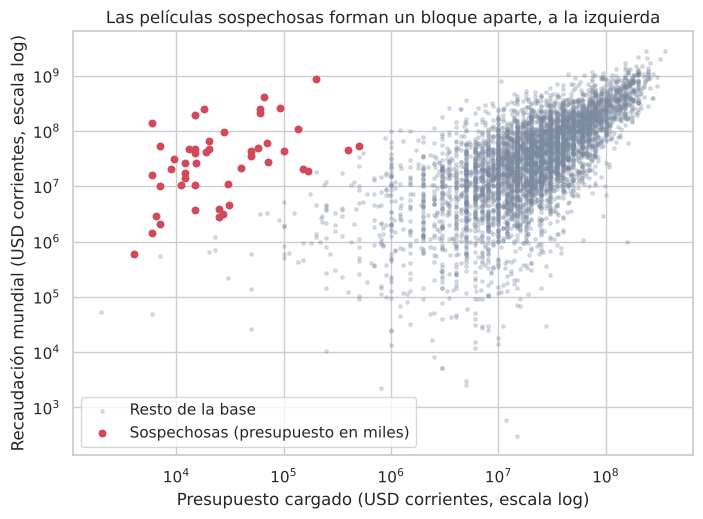

In [11]:
# Gráfico de diagnóstico: presupuesto contra recaudación, en escala logarítmica
figura, eje = plt.subplots(figsize=(8, 5.5))
valido = peliculas["presupuesto_usd"].notna() & (peliculas["recaudacion_mundial_usd"] > 0)
eje.scatter(
    peliculas.loc[valido & ~sospechosas, "presupuesto_usd"],
    peliculas.loc[valido & ~sospechosas, "recaudacion_mundial_usd"],
    s=6,
    alpha=0.25,
    color="#7a8aa0",
    label="Resto de la base",
)
eje.scatter(
    peliculas.loc[sospechosas, "presupuesto_usd"],
    peliculas.loc[sospechosas, "recaudacion_mundial_usd"],
    s=22,
    color="#d1495b",
    label="Sospechosas (presupuesto en miles)",
)
eje.set_xscale("log")
eje.set_yscale("log")
eje.set_xlabel("Presupuesto cargado (USD corrientes, escala log)")
eje.set_ylabel("Recaudación mundial (USD corrientes, escala log)")
eje.set_title("Las películas sospechosas forman un bloque aparte, a la izquierda")
eje.legend()
plt.show()

**Resultado.** 48 películas (0,6% de la base) cumplen la regla de presupuesto menor a USD 1 M y retorno mayor a 100x. El corte no es frágil:
bajarlo a 50x suma 8 películas y subirlo a 200x resta 9. Estas películas son distintas de las realmente baratas: recaudaron una mediana de USD 32,8 M contra 1,5 M de las baratas genuinas
y tienen más del doble de votos (42.000 contra 17.000). Con el presupuesto multiplicado por 1.000 su retorno queda entre 0,35x y 3,16x (cuartiles 25 y 75), casi el mismo rango que el resto de la base (0,72x a 3,65x):
la hipótesis de "presupuesto en miles" explica los datos.

**Es el hallazgo más importante de la limpieza.** Sin esta corrección el retorno medio de la industria sería 26,7x; con ella es 3,3x. La mediana casi no se mueve (1,86x a 1,82x).
Ahí ya se ve por qué el promedio no sirve para decidir en esta industria.

*Limitación.* Dos de las 48 (*Paranormal Activity* y *The Blair Witch Project*) son micropresupuestos reales conocidos que la regla trata como error. Es una decisión conservadora: les quita retorno al terror.

In [12]:
registrar(
    "Presupuesto en miles de dólares (< USD 1 M y retorno > 100x)",
    sospechosas.sum(),
    "Se multiplica por 1.000. Limitación: dos micropresupuestos reales famosos caen en la regla",
)
peliculas["presupuesto_corregido_escala"] = sospechosas  # dejamos marca para poder auditar
peliculas.loc[sospechosas, "presupuesto_usd"] = peliculas.loc[sospechosas, "presupuesto_usd"] * 1000
fotos.append(estado_retorno(peliculas, "4. Presupuestos en escala corregida"))

# Efecto de una decisión discutible: ¿cambia algo si NO corrigiéramos esas filas?
sin_corregir = peliculas.copy()
sin_corregir.loc[sospechosas, "presupuesto_usd"] = (
    sin_corregir.loc[sospechosas, "presupuesto_usd"] / 1000
)
foto_sin = pd.DataFrame([estado_retorno(sin_corregir, "Si NO se corrigiera")]).iloc[0]
foto_con = pd.DataFrame([estado_retorno(peliculas, "Corrigiendo")]).iloc[0]
print(
    f"Retorno medio   : {foto_sin['retorno_medio']:.2f}x sin corregir  vs  {foto_con['retorno_medio']:.2f}x corrigiendo"
)
print(
    f"Retorno mediano : {foto_sin['retorno_mediano']:.2f}x sin corregir  vs  {foto_con['retorno_mediano']:.2f}x corrigiendo"
)

Retorno medio   : 26.70x sin corregir  vs  3.33x corrigiendo
Retorno mediano : 1.86x sin corregir  vs  1.82x corrigiendo


<h3 style='font-weight:bold; color:#0033BB;'>1.7 Normalización de variables categóricas</h3>

Si el mismo género aparece como `Comedia` y `comedia`, `groupby` lo parte en dos filas. La estrategia es pasar todo a minúsculas y sin espacios sobrantes
(`.str.strip().str.lower()`) y usar un diccionario que dice cuál es la forma canónica de cada variante, con las versiones con y sin tilde que aparecen en la base.
Lo que el diccionario no conoce conserva su grafía original.

In [13]:
EQUIV_GENERO = {
    "comedia": "Comedia",
    "accion": "Acción",
    "acción": "Acción",
    "drama": "Drama",
    "policial": "Policial",
    "biografia": "Biografía",
    "biografía": "Biografía",
    "aventura": "Aventura",
    "animacion": "Animación",
    "animación": "Animación",
    "terror": "Terror",
    "fantasia": "Fantasía",
    "fantasía": "Fantasía",
    "misterio": "Misterio",
    "suspenso": "Suspenso",
    "familiar": "Familiar",
    "romance": "Romance",
    "ciencia ficcion": "Ciencia ficción",
    "ciencia ficción": "Ciencia ficción",
    "musical": "Musical",
    "western": "Western",
    "deportiva": "Deportiva",
    "historico": "Histórico",
    "histórico": "Histórico",
}
EQUIV_CLASIFICACION = {
    "atp": "ATP",
    "apta todo publico": "ATP",
    "apta todo público": "ATP",
    "supervision parental": "Supervisión parental",
    "supervisión parental": "Supervisión parental",
    "mayores de 13": "Mayores de 13",
    "mayores de 17": "Mayores de 17",
    "solo adultos": "Solo adultos",
    "sin clasificar": "Sin clasificar",
}
EQUIV_PAIS = {
    "ee.uu.": "Estados Unidos",
    "uk": "Reino Unido",
    "canada": "Canadá",
    "japon": "Japón",
    "mexico": "México",
    "espania": "España",
    "alemania occidental": "Alemania",
}


def normalizar(serie, equivalencias, faltante):
    """Lleva cada valor a su forma canónica; lo que no está en el diccionario se deja limpio."""
    minusculas = serie.str.strip().str.lower()
    canonica = minusculas.map(equivalencias)
    return canonica.fillna(serie.str.strip()).fillna(faltante)


COLUMNAS_CATEGORICAS = ["genero", "clasificacion", "pais_origen", "productora"]
antes_categorias = {columna: peliculas[columna].nunique() for columna in COLUMNAS_CATEGORICAS}
originales_categoricas = peliculas[COLUMNAS_CATEGORICAS].astype(object).fillna("(vacío)")

peliculas["genero"] = normalizar(peliculas["genero"], EQUIV_GENERO, faltante="Sin dato")
# Una clasificación vacía se trata como "Sin clasificar": ya existe esa categoría y el vacío significa lo mismo
peliculas["clasificacion"] = normalizar(
    peliculas["clasificacion"], EQUIV_CLASIFICACION, faltante="Sin clasificar"
)
peliculas["pais_origen"] = normalizar(peliculas["pais_origen"], EQUIV_PAIS, faltante="Sin dato")
# Productoras: espacios al principio, al final o repetidos
peliculas["productora"] = peliculas["productora"].str.replace(r"\s+", " ", regex=True).str.strip()

# es_secuela pasa de "Si"/"No" a booleano; si apareciera otro valor, el assert lo avisa
peliculas["es_secuela"] = peliculas["es_secuela"].map({"Si": True, "No": False})
assert peliculas["es_secuela"].notna().all(), "es_secuela tiene valores fuera de Si/No"
peliculas["es_secuela"] = peliculas["es_secuela"].astype(bool)

despues_categorias = {columna: peliculas[columna].nunique() for columna in COLUMNAS_CATEGORICAS}
display(pd.DataFrame({"antes": antes_categorias, "despues": despues_categorias}))

filas_cambiadas = (
    (peliculas[COLUMNAS_CATEGORICAS].astype(object).fillna("(vacío)") != originales_categoricas)
    .any(axis=1)
    .sum()
)
registrar(
    "Categorías escritas de varias maneras (género, clasificación, país, productora)",
    filas_cambiadas,
    "Se unifican a una grafía canónica; no se pierde ninguna fila",
)

print("\nGéneros después de normalizar:")
print(peliculas["genero"].value_counts().to_string())
print("\nClasificaciones:")
print(peliculas["clasificacion"].value_counts().to_string())

,antes,despues
genero,25,18
clasificacion,10,6
pais_origen,64,58
productora,2744,2531



Géneros después de normalizar:
genero
Comedia            2245
Acción             1705
Drama              1518
Policial            551
Biografía           443
Aventura            427
Animación           338
Terror              322
Fantasía             44
Misterio             20
Suspenso             16
Familiar             11
Ciencia ficción      10
Romance              10
Musical               3
Western               3
Histórico             1
Deportiva             1

Clasificaciones:
clasificacion
Mayores de 17           3697
Mayores de 13           2112
Supervisión parental    1252
Sin clasificar           428
ATP                      153
Solo adultos              26


**Resultado.** Los géneros pasan de 25 a 18 grafías, las clasificaciones de 10 a 6, los países de 64 a 58 y las productoras de 2.744 a 2.531 (espacios sobrantes al principio, al final o repetidos, como ` Universal Pictures` contra `Universal Pictures`).
Una clasificación vacía se trata como *Sin clasificar*: esa categoría ya existe y el vacío significa lo mismo. *Alemania Occidental* se une a *Alemania* porque son pocas películas y la distinción no aporta al análisis de retorno.
Cambia la grafía de 2.682 filas (35% de la base) pero no se pierde ninguna: son cambios de forma, no de contenido.

<h3 style='font-weight:bold; color:#0033BB;'>1.8 Cobertura temporal</h3>

In [14]:
# Fechas: dos formatos conviven en la columna; probamos cada uno
def parsear_fechas(serie):
    """Parsea AAAA-MM-DD y DD/MM/AAAA. Se verificó que las barras son día/mes (hay días > 12)."""
    formato_iso = pd.to_datetime(serie, format="%Y-%m-%d", errors="coerce")
    formato_latino = pd.to_datetime(serie, format="%d/%m/%Y", errors="coerce")
    return formato_iso.fillna(formato_latino)


peliculas["fecha_estreno"] = parsear_fechas(peliculas["fecha_estreno"])
print("Fechas que no se pudieron parsear:", peliculas["fecha_estreno"].isna().sum())

diferencia_anios = (
    (peliculas["fecha_estreno"].dt.year - peliculas["anio_estreno"]).value_counts().sort_index()
)
print("\nAño de la fecha menos año_estreno (0 = coinciden):")
print(diferencia_anios.head(6).to_string())

Fechas que no se pudieron parsear: 0

Año de la fecha menos año_estreno (0 = coinciden):
0    6371
1    1162
2      89
3      16
4       9
5       4


La fecha de estreno puede caer un año después del `anio_estreno` en parte de la base (estreno en otro país, por ejemplo).
Para deflactar se usa `anio_estreno`, que es el año contra el que está medida la columna de dinero. La fecha completa
no se necesita para el análisis.

anio_estreno,1980,1981,1982,1983,1984,1985,1986,2018,2019,2020
peliculas,92.00,113.00,126.00,144.00,168.00,200.00,200.00,200.00,200.00,25.00
pct_sin_presupuesto,49.00,40.00,41.00,38.00,47.00,51.00,50.00,30.00,43.00,40.00


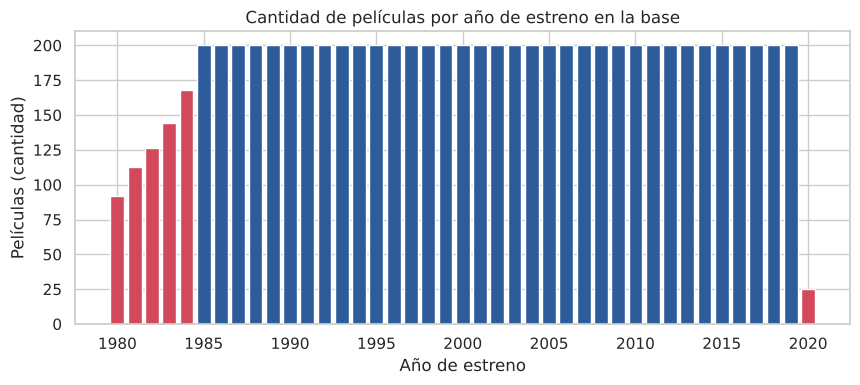

In [15]:
por_anio = peliculas.groupby("anio_estreno").agg(
    peliculas=("id_pelicula", "size"),
    pct_sin_presupuesto=("presupuesto_usd", lambda s: s.isna().mean() * 100),
)
display(por_anio.T.round(0).iloc[:, [0, 1, 2, 3, 4, 5, 6, -3, -2, -1]])

figura, eje = plt.subplots(figsize=(10, 3.8))
colores = [
    "#d1495b" if anio in (1980, 1981, 1982, 1983, 1984, 2020) else "#2e5b9a"
    for anio in por_anio.index
]
eje.bar(por_anio.index, por_anio["peliculas"], color=colores)
eje.set_title("Cantidad de películas por año de estreno en la base")
eje.set_xlabel("Año de estreno")
eje.set_ylabel("Películas (cantidad)")
plt.show()

**Lectura.** Desde 1985 la base tiene unas 200 películas por año, un número casi constante: es una muestra de la industria y no un censo, por eso no sirve para decir cuántas películas se estrenan.
Los años 1980 a 1984 están incompletos (92, 113, 126, 144 y 168 películas) y 2020 tiene solo 25 (año parcial). El porcentaje sin presupuesto tampoco es parejo entre años: ronda el 50% a mediados de los 80.

**Decisión.** No se descarta ningún año de la base. Pero 2020 queda afuera de las tablas y gráficos de tendencia, porque 25 películas dan una mediana inestable (un solo punto estiraba todo el eje del gráfico de la sección 3.1).
Los años 1980-84 se usan, con la advertencia de que su mediana es menos confiable. 2020 sí se usa en el conjunto de prueba (2015-2020).

<h3 style='font-weight:bold; color:#0033BB;'>1.9 Películas sin presupuesto: ¿faltan al azar o por una razón?</h3>

Sin presupuesto no hay retorno, así que estas películas no entran a ningún cálculo de rentabilidad. Antes de aceptar esa pérdida
hay que saber si es un grupo cualquiera (en cuyo caso descartarlas no sesga nada) o si faltan por una razón (en cuyo caso las conclusiones se sesgan).
Se compara el porcentaje de faltantes por década, país y género y también por la recaudación, que sí está cargada.

In [16]:
peliculas["sin_presupuesto"] = peliculas["presupuesto_usd"].isna()
peliculas["decada"] = (peliculas["anio_estreno"] // 10 * 10).astype(str) + "s"
peliculas["origen"] = np.where(
    peliculas["pais_origen"] == "Estados Unidos", "Estados Unidos", "Resto del mundo"
)

print(
    f"Películas sin presupuesto (ya con los centinelas): {peliculas['sin_presupuesto'].sum():,} "
    f"de {len(peliculas):,} ({peliculas['sin_presupuesto'].mean():.1%})"
)


def pct_faltante_por(columna, minimo=30):
    """% de películas sin presupuesto en cada categoría de `columna`."""
    tabla = peliculas.groupby(columna).agg(
        peliculas=("sin_presupuesto", "size"), pct_sin_presupuesto=("sin_presupuesto", "mean")
    )
    tabla["pct_sin_presupuesto"] *= 100
    return tabla.loc[tabla["peliculas"] >= minimo].sort_values(
        "pct_sin_presupuesto", ascending=False
    )


print("\nPor década")
display(pct_faltante_por("decada", minimo=1).sort_index())
print("Por origen")
display(pct_faltante_por("origen"))
print("Por país de origen (países con 30 o más películas)")
display(pct_faltante_por("pais_origen").head(10))
print("Por género (géneros con 30 o más películas)")
display(pct_faltante_por("genero"))

Películas sin presupuesto (ya con los centinelas): 2,219 de 7,668 (28.9%)

Por década


,peliculas,pct_sin_presupuesto
decada,,
1980s,1643,43.94
1990s,2000,31.55
2000s,2000,18.00
2010s,2000,24.80
2020s,25,40.00


Por origen


,peliculas,pct_sin_presupuesto
origen,,
Resto del mundo,2193,49.38
Estados Unidos,5475,20.75


Por país de origen (países con 30 o más películas)


,peliculas,pct_sin_presupuesto
pais_origen,,
India,62,85.48
Italia,61,68.85
Dinamarca,32,65.62
España,47,63.83
Corea del Sur,35,62.86
Francia,279,62.37
Japón,81,60.49
Australia,92,54.35
Irlanda,43,51.16


Por género (géneros con 30 o más películas)


,peliculas,pct_sin_presupuesto
genero,,
Drama,1518,42.49
Comedia,2245,33.54
Biografía,443,28.89
Policial,551,26.86
Aventura,427,23.89
Animación,338,18.93
Terror,322,18.01
Acción,1705,17.01
Fantasía,44,4.55


In [17]:
# Lo decisivo: ¿cómo son las películas sin presupuesto en las columnas que SÍ conocemos?
comparacion_faltantes = peliculas.groupby("sin_presupuesto").agg(
    peliculas=("id_pelicula", "size"),
    recaudacion_mediana_usd=("recaudacion_mundial_usd", "median"),
    votos_medianos=("cantidad_votos", "median"),
    puntaje_mediano=("puntaje_imdb", "median"),
)
comparacion_faltantes.index = ["Con presupuesto", "Sin presupuesto"]
display(comparacion_faltantes)

# Quintil de recaudación (1 = el 20% que menos recauda), armado con quantile y una función
cortes_recaudacion = peliculas["recaudacion_mundial_usd"].quantile([0.2, 0.4, 0.6, 0.8]).tolist()


def quintil_de_recaudacion(valor):
    """Devuelve 1 a 5 según el quintil de recaudación de la película."""
    if pd.isna(valor):
        return np.nan
    for numero, corte in enumerate(cortes_recaudacion, start=1):
        if valor <= corte:
            return numero
    return 5


peliculas["quintil_recaudacion"] = peliculas["recaudacion_mundial_usd"].apply(
    quintil_de_recaudacion
)
print("% sin presupuesto según el quintil de recaudación:")
display(
    peliculas.groupby("quintil_recaudacion")["sin_presupuesto"]
    .mean()
    .mul(100)
    .to_frame("pct_sin_presupuesto")
)

,peliculas,recaudacion_mediana_usd,votos_medianos,puntaje_mediano
Con presupuesto,5449,"36,606,743.00","51,000.00",6.45
Sin presupuesto,2219,"4,150,418.50","8,900.00",6.50


% sin presupuesto según el quintil de recaudación:


,pct_sin_presupuesto
quintil_recaudacion,
1.00,60.29
2.00,41.24
3.00,24.88
4.00,9.63
5.00,3.68


**Lectura.** Faltan 2.219 presupuestos (28,9% de la base, contando los ceros y -1 que eran centinelas). No faltan al azar:

- por década: 43,9% en los 80, 31,6% en los 90, 18,0% en los 2000 y 24,8% en los 2010;
- por origen: 49,4% en el resto del mundo contra 20,8% en Estados Unidos (India llega a 85,5%);
- por género: 42,5% en drama y 33,5% en comedia, contra 17,0% en acción y 18,0% en terror.

Y lo decisivo: las películas sin presupuesto son chicas. Su recaudación mediana es USD 4,2 M contra 36,6 M de las que sí lo tienen, y el presupuesto falta en el 60% de las películas del quintil de menor recaudación
contra el 3,7% del quintil de mayor recaudación. Faltan las películas pequeñas, extranjeras, antiguas y de drama o comedia, que son justo donde el fracaso es más frecuente.

**Decisión.** Descartar es inevitable (no se puede inventar un presupuesto), pero no se descarta *en silencio*. Se agrega un escenario alternativo con imputación por grupo:
a cada película sin presupuesto se le asigna la mediana del presupuesto de las películas que sí lo tienen y que están en su mismo quintil de recaudación y en su mismo origen (EE.UU. o resto del mundo).
El supuesto es que, dado cuánto recaudó y de dónde es, una película se parece en presupuesto a las demás de su grupo. No se puede verificar con los datos, así que el escenario no es "la verdad":
sirve para ver cuánto cambian las conclusiones si los faltantes se parecen a lo observado.

In [18]:
# Imputación por grupo: la mediana del presupuesto de cada (quintil de recaudación, origen)
peliculas["presupuesto_imputado"] = peliculas.groupby(["quintil_recaudacion", "origen"])[
    "presupuesto_usd"
].transform("median")

con_recaudacion_sin_presupuesto = (
    peliculas["sin_presupuesto"] & peliculas["recaudacion_mundial_usd"].notna()
)
print(
    f"Películas a las que se les imputa presupuesto en el escenario: {con_recaudacion_sin_presupuesto.sum():,}"
)
registrar(
    "Películas sin presupuesto (centinelas incluidos)",
    peliculas["sin_presupuesto"].sum(),
    "Se excluyen del cálculo de retorno; el escenario alternativo les imputa la mediana de su grupo",
)

Películas a las que se les imputa presupuesto en el escenario: 2,090


<h2 style='font-weight:bold; color:#003366;'>Etapa 2: Creación de variables</h2>

<h3 style='font-weight:bold; color:#0033BB;'>2.1 Dólares constantes</h3>

**Qué hace la operación.** El IPC mide cuánto cuesta una canasta fija de bienes en cada año. Si el IPC de 1985 es 107,6 y el de 2020 es 258,8,
la misma canasta cuesta 2,4 veces más en 2020, así que un dólar de 1985 compra lo que 2,4 dólares de 2020. Para llevar un monto de cualquier año a dólares de 2020 se multiplica por

`factor = IPC(2020) / IPC(año de estreno)`

El resultado no cambia lo que se compró, solo la unidad de medida: pasa de "dólares del año X" a "dólares de 2020", y con eso dos películas de distintas épocas se pueden comparar.

In [19]:
peliculas = peliculas.merge(
    ipc.rename(columns={"anio": "anio_estreno"}), on="anio_estreno", how="left", validate="m:1"
)
ipc_base = ipc.loc[ipc["anio"] == ANIO_BASE, "ipc_eeuu"].iloc[0]
peliculas["factor_inflacion"] = ipc_base / peliculas["ipc_eeuu"]

peliculas["presupuesto_real"] = peliculas["presupuesto_usd"] * peliculas["factor_inflacion"]
peliculas["recaudacion_real"] = peliculas["recaudacion_mundial_usd"] * peliculas["factor_inflacion"]

print(f"Películas sin IPC asignado: {peliculas['ipc_eeuu'].isna().sum()}")
display(
    peliculas.loc[
        peliculas["titulo"].isin(["E.T. the Extra-Terrestrial", "Jurassic World", "Titanic"]),
        [
            "titulo",
            "anio_estreno",
            "factor_inflacion",
            "recaudacion_mundial_usd",
            "recaudacion_real",
        ],
    ]
)

Películas sin IPC asignado: 0


,titulo,anio_estreno,factor_inflacion,recaudacion_mundial_usd,recaudacion_real
209,E.T. the Extra-Terrestrial,1982,2.68,"792,910,554.00","2,126,479,288.86"
3045,Titanic,1997,1.61,"2,201,647,264.00","3,550,070,479.27"
6653,Jurassic World,2015,1.09,"1,670,516,444.00","1,824,175,762.48"


*E.T.* recaudó USD 793 M corrientes en 1982 y esa cifra, llevada a dólares de 2020, es casi 2,7 veces más grande. Es la diferencia entre
mirar el cartel y mirar el poder de compra.

<h3 style='font-weight:bold; color:#0033BB;'>2.2 Retorno y regla del 2,5×</h3>

In [20]:
peliculas["roi"] = peliculas["recaudacion_mundial_usd"] / peliculas["presupuesto_usd"]
peliculas["recupera"] = np.where(
    peliculas["roi"].notna(), peliculas["roi"] >= UMBRAL_RECUPERO, np.nan
)
peliculas["no_recupera"] = (
    1 - peliculas["recupera"]
)  # 1 = perdió plata en salas (para promediar como probabilidad)

# Comprobación: el retorno es el mismo en dólares corrientes y constantes
roi_real = peliculas["recaudacion_real"] / peliculas["presupuesto_real"]
print(
    "Máxima diferencia entre retorno corriente y retorno en constantes:",
    f"{(peliculas['roi'] - roi_real).abs().max():.1e}",
)

Máxima diferencia entre retorno corriente y retorno en constantes: 1.4e-14


**Una propiedad útil que hay que entender.** El retorno es un cociente entre dos montos del *mismo* año, así que el factor de inflación se cancela:
el retorno corriente y el constante son idénticos (la comprobación de arriba lo muestra). La inflación importa para comparar montos entre épocas
(¿creció la industria?, ¿cuánto cuesta una película típica hoy?) pero no para comparar retornos.

<h3 style='font-weight:bold; color:#0033BB;'>2.3 Variables adicionales</h3>

In [21]:
def tramo_de_presupuesto(valor):
    """Tramo de presupuesto en dólares constantes de 2020."""
    if pd.isna(valor):
        return np.nan
    if valor < 5e6:
        return "Menos de 5 M"
    elif valor < 20e6:
        return "5 a 20 M"
    elif valor < 50e6:
        return "20 a 50 M"
    elif valor < 100e6:
        return "50 a 100 M"
    return "Más de 100 M"


ORDEN_TRAMOS = ["Menos de 5 M", "5 a 20 M", "20 a 50 M", "50 a 100 M", "Más de 100 M"]

# Agrupamos los géneros chicos (menos de MIN_PELICULAS películas en la base) para que los segmentos se puedan interpretar
conteo_genero = peliculas["genero"].value_counts()
generos_chicos = conteo_genero[conteo_genero < MIN_PELICULAS].index


def agregar_variables(df):
    """Agrega las variables de análisis a una tabla con presupuesto y recaudación (sirve para las dos bases)."""
    df = df.copy()
    df["roi"] = df["recaudacion_mundial_usd"] / df["presupuesto_usd"]
    df["no_recupera"] = np.where(df["roi"] >= UMBRAL_RECUPERO, 0, 1)  # 1 = perdió plata en salas
    df["presupuesto_real"] = df["presupuesto_usd"] * df["factor_inflacion"]
    df["recaudacion_real"] = df["recaudacion_mundial_usd"] * df["factor_inflacion"]
    # Tramo de presupuesto en dólares constantes (para comparar películas de distinta época)
    df["tramo_presupuesto"] = df["presupuesto_real"].apply(tramo_de_presupuesto)
    df["franquicia"] = np.where(df["es_secuela"], "Franquicia", "Original")
    df["log_votos"] = np.log10(df["cantidad_votos"])
    df["genero_agrupado"] = np.where(
        df["genero"].isin(generos_chicos), "Otros géneros", df["genero"]
    )
    return df


# Base de trabajo: películas con presupuesto y recaudación
analisis = agregar_variables(peliculas.loc[peliculas["roi"].notna()])

# Base del escenario alternativo: se agregan las películas sin presupuesto (con la mediana de su grupo)
base_imputada = peliculas.dropna(subset=["recaudacion_mundial_usd"]).copy()
base_imputada["presupuesto_usd"] = base_imputada["presupuesto_usd"].fillna(
    base_imputada["presupuesto_imputado"]
)
base_imputada = agregar_variables(base_imputada)

print(f"Películas en la base limpia                      : {len(peliculas):,}")
print(
    f"Películas con retorno calculable (base de trabajo): {len(analisis):,} ({len(analisis) / len(peliculas):.1%})"
)
print(f"Películas en el escenario con presupuestos imputados: {len(base_imputada):,}")
print(f"Géneros agrupados en 'Otros'                      : {', '.join(generos_chicos)}")

Películas en la base limpia                      : 7,668
Películas con retorno calculable (base de trabajo): 5,389 (70.3%)
Películas en el escenario con presupuestos imputados: 7,479
Géneros agrupados en 'Otros'                      : Misterio, Suspenso, Familiar, Ciencia ficción, Romance, Musical, Western, Histórico, Deportiva


In [22]:
# Efecto de los faltantes sobre las conclusiones: base de trabajo contra escenario con presupuestos imputados
resumen_global = pd.DataFrame(
    {
        "retorno_mediano": [analisis["roi"].median(), base_imputada["roi"].median()],
        "p_perder": [analisis["no_recupera"].mean(), base_imputada["no_recupera"].mean()],
        "peliculas": [len(analisis), len(base_imputada)],
    },
    index=["Observado (solo con presupuesto)", "Con presupuestos imputados"],
)
display(resumen_global)

genero_observado = analisis.groupby("genero_agrupado")["roi"].median()
genero_imputado = base_imputada.groupby("genero_agrupado")["roi"].median()
comparacion_generos = pd.DataFrame(
    {
        "mediana_observada": genero_observado,
        "mediana_imputada": genero_imputado,
        "puesto_observado": genero_observado.rank(ascending=False),
        "puesto_imputado": genero_imputado.rank(ascending=False),
    }
).sort_values("mediana_observada", ascending=False)
display(comparacion_generos)

,retorno_mediano,p_perder,peliculas
Observado (solo con presupuesto),1.82,0.61,5389
Con presupuestos imputados,1.21,0.71,7479


,mediana_observada,mediana_imputada,puesto_observado,puesto_imputado
genero_agrupado,,,,
Terror,3.05,2.34,1.00,2.00
Animación,2.92,2.49,2.00,1.00
Fantasía,2.14,2.14,3.00,3.00
Acción,1.87,1.62,4.00,4.00
Otros géneros,1.83,0.79,5.00,9.00
Aventura,1.82,1.38,6.00,5.00
Comedia,1.78,1.10,7.00,6.00
Drama,1.53,0.68,8.00,10.00
Biografía,1.48,1.08,9.00,7.00


**Efecto de la decisión sobre las conclusiones.** Trabajar solo con las películas que tienen presupuesto (70,3% de la base) sobreestima el desempeño de la industria:
con presupuestos imputados la mediana del retorno pasa de 1,82x a 1,21x y la probabilidad de perder plata sube de 61% a 71%.

Lo que sí sobrevive es el orden: Animación y Terror siguen en los dos primeros puestos (se intercambian el 1º y el 2º) y Drama y Policial siguen entre los últimos.
Las conclusiones sobre *qué clase de película es mejor* son más firmes que las conclusiones sobre *cuánto rinde en términos absolutos*.
Un límite del escenario: como la imputación asigna un presupuesto típico, no sirve para comparar segmentos definidos por el presupuesto (como el tramo "menos de 5 M"), porque por construcción las películas imputadas nunca caen en los tramos extremos.

In [23]:
# Cierre de la etapa 1: bitácora de cambios y efecto sobre el retorno
bitacora_df = pd.DataFrame(bitacora)
display(bitacora_df.style.format({"pct_base_inicial": "{:.2f}%"}))
print("\nEl retorno de la industria, antes y después de cada corrección:")
display(pd.DataFrame(fotos).set_index("etapa"))
bitacora_df.to_csv(CARPETA_SALIDAS / "bitacora_limpieza.csv", index=False)

,paso,filas_afectadas,pct_base_inicial,decision
0,Filas exactamente duplicadas,58,0.75%,Se borran: carga doble del mismo registro
1,Películas repetidas con presupuesto distinto,14,0.18%,"Se conserva el id original (<90000), cuyo presupuesto es redondo como el resto de la base"
2,"Centinela en duracion_minutos ([0, 999])",34,0.44%,"Se reemplaza por NaN: es un 'no sé', no un dato"
3,Centinela en puntaje_imdb ([0]),22,0.28%,"Se reemplaza por NaN: es un 'no sé', no un dato"
4,"Centinela en presupuesto_usd ([0, -1])",48,0.62%,"Se reemplaza por NaN: es un 'no sé', no un dato"
5,Recaudación con signo negativo,11,0.14%,Se pasa a valor absoluto: magnitud coherente con una película real
6,Presupuesto en miles de dólares (< USD 1 M y retorno > 100x),48,0.62%,Se multiplica por 1.000. Limitación: dos micropresupuestos reales famosos caen en la regla
7,"Categorías escritas de varias maneras (género, clasificación, país, productora)",2682,34.65%,Se unifican a una grafía canónica; no se pierde ninguna fila
8,Películas sin presupuesto (centinelas incluidos),2219,28.67%,Se excluyen del cálculo de retorno; el escenario alternativo les imputa la mediana de su grupo



El retorno de la industria, antes y después de cada corrección:


,filas,con_retorno_calculable,retorno_medio,retorno_mediano,pct_recupera
etapa,,,,,
0. Base cruda,7740,5443,26.46,1.86,39.17
1. Sin duplicados exactos,7682,5403,26.63,1.86,39.18
2. Sin películas repetidas,7668,5389,26.70,1.86,39.23
3. Sin centinelas ni signos,7668,5389,26.70,1.86,39.27
4. Presupuestos en escala corregida,7668,5389,3.33,1.82,38.67


**Lectura de la bitácora.** Casi todas las correcciones afectan menos del 1% de la base y no mueven el retorno mediano (se mantiene en 1,86x hasta la corrección de escala y queda en 1,82x).
Tres cambios pesan más: 2.682 filas (35%) cambian de grafía sin perder contenido; 2.219 presupuestos faltantes (el 28,7% de la base inicial) que se excluyen del cálculo de retorno;
y 48 presupuestos (0,6%) cambian de escala, que es la corrección que más mueve el retorno medio (de 26,7x a 3,3x). Conclusión metodológica: el retorno mediano es robusto a la limpieza y el medio no.

<h2 style='font-weight:bold; color:#003366;'>Etapa 3: Análisis de negocio</h2>

<h3 style='font-weight:bold; color:#0033BB;'>3.1 ¿La industria creció?</h3>

Se usa la mediana de la recaudación de las películas de cada año, no el total, porque la base tiene unas 200 películas por año
(no es un censo de la industria) y el total solo reflejaría cuántas películas hay cargadas. La mediana responde a otra pregunta: ¿cuánto recauda una película típica?

,peliculas,mediana_corriente_M,mediana_constante_M
decada,,,
1980s,1521,8.62,20.92
1990s,1957,12.87,22.13
2000s,1994,40.41,53.42
2010s,1992,41.67,45.79


Crecimiento de la mediana entre la década de 1980 y la de 2010: +383% corriente, +119% constante


Inflación de EE.UU. entre 1985 y 2015 (IPC): +120%


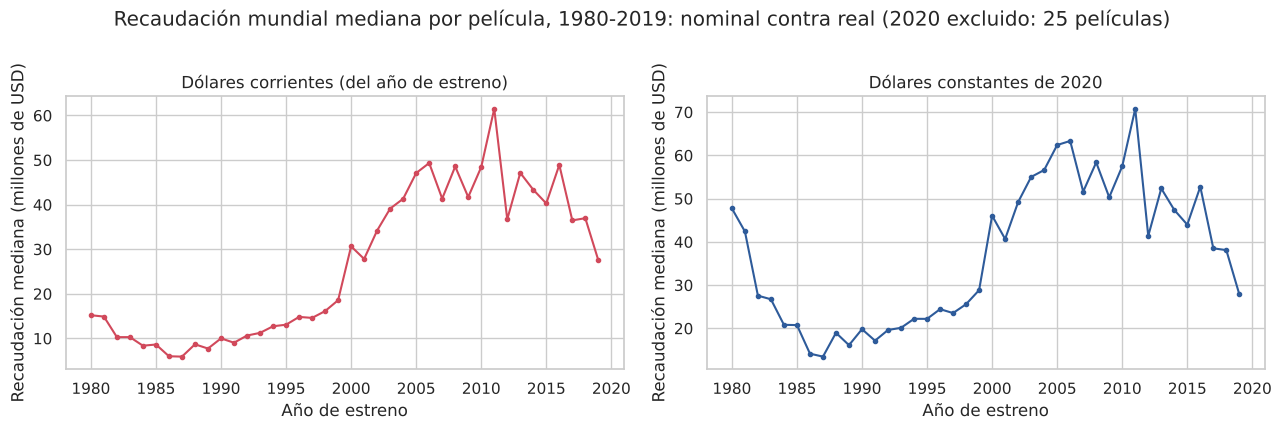

In [24]:
con_recaudacion = peliculas.dropna(subset=["recaudacion_mundial_usd"])
serie_anual = con_recaudacion.groupby("anio_estreno").agg(
    peliculas=("id_pelicula", "size"),
    mediana_corriente=("recaudacion_mundial_usd", "median"),
    mediana_constante=("recaudacion_real", "median"),
)

# Por década, sin 2020 (solo 25 películas, año incompleto)
por_decada = (
    con_recaudacion.loc[con_recaudacion["anio_estreno"] < 2020]
    .groupby("decada")
    .agg(
        peliculas=("id_pelicula", "size"),
        mediana_corriente_M=("recaudacion_mundial_usd", lambda s: s.median() / 1e6),
        mediana_constante_M=("recaudacion_real", lambda s: s.median() / 1e6),
    )
)
display(por_decada)

crecimiento_corriente = (
    por_decada["mediana_corriente_M"].iloc[-1] / por_decada["mediana_corriente_M"].iloc[0] - 1
)
crecimiento_constante = (
    por_decada["mediana_constante_M"].iloc[-1] / por_decada["mediana_constante_M"].iloc[0] - 1
)
inflacion_acumulada = (
    ipc.loc[ipc["anio"] == 2015, "ipc_eeuu"].iloc[0]
    / ipc.loc[ipc["anio"] == 1985, "ipc_eeuu"].iloc[0]
    - 1
)
print(
    f"Crecimiento de la mediana entre la década de 1980 y la de 2010: {crecimiento_corriente:+.0%} corriente, {crecimiento_constante:+.0%} constante"
)
print(f"Inflación de EE.UU. entre 1985 y 2015 (IPC): {inflacion_acumulada:+.0%}")

serie_anual_completa = serie_anual.loc[
    serie_anual.index < 2020
]  # 2020 tiene solo 25 películas y distorsiona el eje
figura, ejes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
for eje, columna, titulo, color in [
    (ejes[0], "mediana_corriente", "Dólares corrientes (del año de estreno)", "#d1495b"),
    (ejes[1], "mediana_constante", "Dólares constantes de 2020", "#2e5b9a"),
]:
    eje.plot(
        serie_anual_completa.index,
        serie_anual_completa[columna] / 1e6,
        color=color,
        marker="o",
        markersize=3,
    )
    eje.set_title(titulo)
    eje.set_xlabel("Año de estreno")
    eje.set_ylabel("Recaudación mediana (millones de USD)")
figura.suptitle(
    "Recaudación mundial mediana por película, 1980-2019: nominal contra real (2020 excluido: 25 películas)",
    y=1.02,
)
plt.tight_layout()
guardar_figura(figura, "01_evolucion_nominal_vs_real")
plt.show()

**Lectura.** En dólares corrientes, la recaudación mediana por película pasa de USD 8,6 M en la década de 1980 a USD 41,7 M en la de 2010: +383%.
En dólares constantes de 2020 el salto es de 20,9 M a 45,8 M: +119%. La inflación acumulada de EE.UU. entre 1985 y 2015 fue de +120%, así que los precios más que se duplicaron.
Aproximadamente la mitad del salto nominal (en términos logarítmicos) es inflación y no crecimiento real.

**Conclusión sobre la inflación.** Comparar dólares corrientes de épocas distintas exagera el crecimiento: el gráfico de la izquierda muestra una industria que casi se quintuplica y el de la derecha, una película típica que se duplica.
Además el crecimiento real se concentra entre los 90 y los 2000: la mediana real de los 2010 (45,8 M) es 14% menor que la de los 2000 (53,4 M). Sin el IPC se concluiría que la industria sigue acelerando, y la película típica dejó de crecer.
Advertencia: la base es una muestra de unas 200 películas por año, así que esto habla de la película típica de la base, no del tamaño de la industria.

<h3 style='font-weight:bold; color:#0033BB;'>3.2 ¿Cuánto rinde cada tipo de película?</h3>

In [25]:
def metricas_segmento(df, columna):
    """Retorno medio y mediano, probabilidad de perder y peor decil por categoría de `columna`."""
    return df.groupby(columna).agg(
        n=("roi", "size"),
        retorno_medio=("roi", "mean"),
        retorno_mediano=("roi", "median"),
        p_perder=("no_recupera", "mean"),
        peor_decil=("roi", lambda serie: serie.quantile(0.10)),
    )


def metricas_con_escenario(df, df_imputada, columna):
    """Las mismas métricas y, al lado, mediana y probabilidad de perder del escenario con presupuestos imputados."""
    imputado = df_imputada.groupby(columna).agg(
        retorno_mediano_imputado=("roi", "median"),
        p_perder_imputada=("no_recupera", "mean"),
    )
    return metricas_segmento(df, columna).join(imputado)


por_genero = metricas_con_escenario(analisis, base_imputada, "genero_agrupado").sort_values(
    "retorno_mediano", ascending=False
)
por_genero["media_sobre_mediana"] = por_genero["retorno_medio"] / por_genero["retorno_mediano"]
print(
    "Retorno por género (ordenado por mediana). 'media_sobre_mediana' mide cuánto infla el promedio."
)
display(por_genero[["n", "retorno_medio", "retorno_mediano", "media_sobre_mediana"]])

print(
    f"Toda la industria: retorno medio {analisis['roi'].mean():.2f}x | mediano {analisis['roi'].median():.2f}x"
)

Retorno por género (ordenado por mediana). 'media_sobre_mediana' mide cuánto infla el promedio.


,n,retorno_medio,retorno_mediano,media_sobre_mediana
genero_agrupado,,,,
Terror,254,8.18,3.05,2.68
Animación,273,4.00,2.92,1.37
Fantasía,42,2.52,2.14,1.17
Acción,1405,2.71,1.87,1.45
Otros géneros,41,4.41,1.83,2.41
Aventura,323,2.80,1.82,1.54
Comedia,1479,3.34,1.78,1.88
Drama,862,3.58,1.53,2.34
Biografía,312,2.71,1.48,1.84


Toda la industria: retorno medio 3.33x | mediano 1.82x


**¿Quién rompe el promedio?** Se miran las películas con retorno más alto y cuánto del retorno total de cada género explican unas pocas.

In [26]:
columnas_ver = ["titulo", "anio_estreno", "genero", "presupuesto_real", "recaudacion_real", "roi"]
top_retorno = analisis.sort_values("roi", ascending=False)[columnas_ver].head(12)
display(
    top_retorno.assign(
        presupuesto_real=lambda t: t["presupuesto_real"] / 1e6,
        recaudacion_real=lambda t: t["recaudacion_real"] / 1e6,
    ).rename(columns={"presupuesto_real": "presup_M_2020", "recaudacion_real": "recaud_M_2020"})
)


def concentracion_top(retornos, cantidad=5):
    """Qué fracción de la suma de retornos aportan las `cantidad` mejores películas."""
    ordenados = retornos.sort_values(ascending=False)
    return ordenados.head(cantidad).sum() / ordenados.sum()


concentracion = analisis.groupby("genero_agrupado")["roi"].agg(concentracion_top)
print("Fracción de la suma de retornos que explican las 5 mejores películas de cada género:")
print(concentracion.sort_values(ascending=False).round(2).head(5).to_string())

# Si sacamos las 5 mejores de cada género, ¿cómo queda el promedio?
promedio_sin_top5 = {}
for genero, grupo in analisis.groupby("genero_agrupado"):
    promedio_sin_top5[genero] = grupo["roi"].sort_values(ascending=False).iloc[5:].mean()
comparacion_promedio = pd.DataFrame(
    {
        "promedio": por_genero["retorno_medio"],
        "promedio_sin_top5": pd.Series(promedio_sin_top5),
        "mediana": por_genero["retorno_mediano"],
    }
)
display(comparacion_promedio.sort_values("promedio", ascending=False).head(6))

,titulo,anio_estreno,genero,presup_M_2020,recaud_M_2020,roi
6237,The Devil Inside,2012,Terror,1.13,114.70,101.76
6614,The Quiet Ones,2014,Terror,0.22,19.50,89.18
4456,Saw,2004,Terror,1.64,142.36,86.59
7330,Searching,2018,Drama,0.91,77.78,85.75
4507,Primer,2004,Drama,0.01,0.75,77.92
209,E.T. the Extra-Terrestrial,1982,Familiar,28.16,"2,126.48",75.52
4080,My Big Fat Greek Wedding,2002,Comedia,7.19,530.47,73.75
3089,The Full Monty,1997,Comedia,5.64,415.92,73.70
5,Friday the 13th,1980,Terror,1.73,124.86,72.28
5406,Fireproof,2008,Drama,0.60,40.24,66.95


Fracción de la suma de retornos que explican las 5 mejores películas de cada género:
genero_agrupado
Otros géneros   0.62
Fantasía        0.33
Terror          0.20
Policial        0.12
Animación       0.11


,promedio,promedio_sin_top5,mediana
Terror,8.18,6.67,3.05
Otros géneros,4.41,1.89,1.83
Animación,4.00,3.60,2.92
Drama,3.58,3.22,1.53
Comedia,3.34,3.14,1.78
Aventura,2.80,2.56,1.82


In [27]:
# Sensibilidad: ¿qué pasa con Terror si Paranormal Activity y The Blair Witch Project se dejan con su presupuesto original?
# (dos micropresupuestos reales conocidos que la regla de la sección 1.6 había multiplicado por 1.000)
EXCEPCIONES = ["Paranormal Activity", "The Blair Witch Project"]
es_excepcion = analisis["titulo"].isin(EXCEPCIONES)
roi_original = analisis["roi"].where(
    ~es_excepcion, analisis["roi"] * 1000
)  # sin multiplicar el presupuesto por 1.000
es_terror = analisis["genero"] == "Terror"

sensibilidad = pd.DataFrame(
    {
        "Con la corrección (base del análisis)": {
            "retorno_medio": analisis.loc[es_terror, "roi"].mean(),
            "retorno_mediano": analisis.loc[es_terror, "roi"].median(),
            "p_perder": (analisis.loc[es_terror, "roi"] < UMBRAL_RECUPERO).mean(),
        },
        "Dejando esas dos como estaban": {
            "retorno_medio": roi_original[es_terror].mean(),
            "retorno_mediano": roi_original[es_terror].median(),
            "p_perder": (roi_original[es_terror] < UMBRAL_RECUPERO).mean(),
        },
    }
)
display(sensibilidad)
print(
    "Retornos de esas dos películas: con corrección",
    analisis.loc[es_excepcion, ["titulo", "roi"]].set_index("titulo")["roi"].round(1).to_dict(),
    "| sin corrección",
    roi_original[es_excepcion].round(0).to_dict().values(),
)

,Con la corrección (base del análisis),Dejando esas dos como estaban
retorno_medio,8.18,75.17
retorno_mediano,3.05,3.05
p_perder,0.43,0.43


Retornos de esas dos películas: con corrección {'The Blair Witch Project': 4.1, 'Paranormal Activity': 12.9} | sin corrección dict_values([4144.0, 12890.0])


**Resultado.** Dejar *Paranormal Activity* y *The Blair Witch Project* con su presupuesto original dispara el promedio de Terror (de 8,18x a 75,17x) y no cambia su mediana (3,05x) ni su probabilidad de perder (43%): las dos películas están por encima de la mediana en los dos casos, así que no la mueven.
Como la tesis se apoya en medianas y en probabilidades de perder, y no en el promedio, la decisión sobre estas dos películas no cambia las conclusiones. Cambiaría la lectura del promedio de Terror, que ya se descarta en el notebook por engañoso.
Que sean micropresupuestos reales lo sabemos por conocimiento general y no por los datos: la regla las trata como a las otras 46, y esta celda muestra el efecto de esa decisión.

**Lectura.** En toda la industria el retorno medio es 3,33x y el mediano 1,82x. En Terror la diferencia es de 2,7 veces (8,18x contra 3,05x) y en Drama de 2,3 veces (3,58x contra 1,53x).

**¿Error de carga o realidad del negocio?** Se miraron las películas que rompen el promedio. Después de corregir la escala de los presupuestos, las de mayor retorno son *The Devil Inside* (102x), *The Quiet Ones* (89x), *Saw* (87x),
*Searching* (86x), *Primer* (78x), *E.T.* (75x), *My Big Fat Greek Wedding* (74x), *The Full Monty* (74x) y *Friday the 13th* (72x). Presupuestos y recaudaciones son coherentes entre sí (películas de muy bajo costo que recaudan decenas o cientos de millones):
**son la realidad del negocio, no errores**. Se conservan. Esto es el corazón de la industria: pocas películas muy baratas con retornos enormes que arrastran el promedio, y una mayoría que no recupera.
Por eso se usan medianas y probabilidades de pérdida en lugar de promedios. En Terror las 5 mejores películas explican el 20% de la suma de retornos, y aun sin ellas el promedio (6,67x) sigue siendo el doble de la mediana: la cola es ancha y no son tres casos aislados.

**Otras categorías**: clasificación por edades, origen y franquicia.

In [28]:
por_clasificacion = metricas_segmento(analisis, "clasificacion").sort_values(
    "retorno_mediano", ascending=False
)
por_franquicia = metricas_segmento(analisis, "franquicia").sort_values(
    "retorno_mediano", ascending=False
)
por_origen = metricas_segmento(analisis, "origen").sort_values("retorno_mediano", ascending=False)
paises_grandes = analisis["pais_origen"].value_counts()
paises_grandes = paises_grandes[paises_grandes >= MIN_PELICULAS].index
por_pais = metricas_segmento(
    analisis[analisis["pais_origen"].isin(paises_grandes)], "pais_origen"
).sort_values("retorno_mediano", ascending=False)

for nombre, tabla in [
    ("Clasificación por edades", por_clasificacion),
    ("Franquicia", por_franquicia),
    ("Origen", por_origen),
    ("País (30 o más películas)", por_pais),
]:
    print(nombre)
    display(tabla)

Clasificación por edades


,n,retorno_medio,retorno_mediano,p_perder,peor_decil
clasificacion,,,,,
ATP,110,4.19,2.69,0.48,0.48
Mayores de 13,1713,3.32,2.07,0.58,0.41
Supervisión parental,898,3.34,2.03,0.59,0.35
Solo adultos,13,2.73,1.61,0.62,0.32
Mayores de 17,2579,3.28,1.55,0.65,0.20
Sin clasificar,76,3.89,1.02,0.67,0.04


Franquicia


,n,retorno_medio,retorno_mediano,p_perder,peor_decil
franquicia,,,,,
Franquicia,573,4.22,2.97,0.41,0.77
Original,4816,3.22,1.68,0.64,0.25


Origen


,n,retorno_medio,retorno_mediano,p_perder,peor_decil
origen,,,,,
Estados Unidos,4290,3.39,1.95,0.60,0.30
Resto del mundo,1099,3.10,1.33,0.68,0.16


País (30 o más películas)


,n,retorno_medio,retorno_mediano,p_perder,peor_decil
pais_origen,,,,,
Japón,31,4.45,2.79,0.48,0.25
Estados Unidos,4290,3.39,1.95,0.60,0.30
Australia,42,4.25,1.53,0.60,0.21
Reino Unido,489,2.88,1.30,0.70,0.17
Francia,105,2.69,1.15,0.75,0.09
Alemania,82,2.09,1.04,0.78,0.17
Canadá,111,3.79,0.83,0.72,0.25


**Lectura.**

- **Clasificación por edades.** La clasificación ATP tiene la mediana más alta (2,69x, 48% de pérdida, pero solo 110 películas); le siguen *Mayores de 13* y *Supervisión parental* (2,07x y 2,03x, 58% y 59% de pérdida).
  *Mayores de 17*, que es la categoría más grande (2.579 películas), rinde 1,55x y pierde en 65% de los casos. *Sin clasificar* es la peor (1,02x). Mientras más amplia la audiencia posible, mejor el perfil.
- **Franquicia.** Las franquicias tienen una mediana de 2,97x y pierden en 41% de los casos, contra 1,68x y 64% de las películas originales. El peor decil de una franquicia es 0,77x contra 0,25x en una original.
- **Origen.** Las películas estadounidenses rinden 1,95x (60% de pérdida) y las del resto del mundo 1,33x (68%). Entre los países con 30 películas o más, Reino Unido (1,30x), Francia (1,15x) y Alemania (1,04x) quedan por debajo.
  Japón sale primero con 2,79x pero con solo 31 películas, así que no se interpreta.

Dos cautelas. La franquicia existe porque la película anterior funcionó (sesgo de supervivencia), y el fondo tendría que comprar o asociarse con los derechos. Y el origen está muy afectado por los faltantes: para el resto del mundo falta el presupuesto del 49% de las películas.

**Puntaje de IMDb y retorno.** El retorno tiene una cola muy larga, así que la correlación se calcula sobre los logaritmos de las variables de dinero y de votos, que es lo que la vuelve interpretable.

Correlación de cada variable con el retorno (log):
Puntaje IMDb         0.24
Votos (log)          0.53
Duración             0.04
Presupuesto (log)   -0.03
Recaudación (log)    0.75


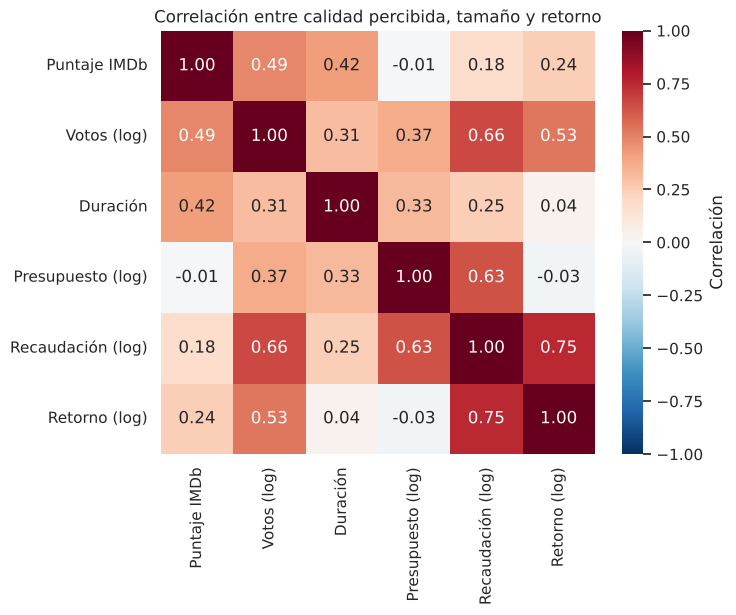

Retorno por tramo de puntaje IMDb


,n,mediana,p_perder
tramo_imdb,,,
1. menos de 5,372,0.97,0.76
2. de 5 a 6,1178,1.32,0.71
3. de 6 a 7,2266,1.72,0.65
4. de 7 a 8,1359,2.68,0.48
5. 8 o más,196,4.82,0.24


In [29]:
base_corr = pd.DataFrame(
    {
        "Puntaje IMDb": analisis["puntaje_imdb"],
        "Votos (log)": analisis["log_votos"],
        "Duración": analisis["duracion_minutos"],
        "Presupuesto (log)": np.log10(analisis["presupuesto_real"]),
        "Recaudación (log)": np.log10(analisis["recaudacion_real"]),
        "Retorno (log)": np.log10(analisis["roi"]),
    }
)
matriz = base_corr.corr()
print("Correlación de cada variable con el retorno (log):")
print(matriz["Retorno (log)"].drop("Retorno (log)").round(2).to_string())

figura, eje = plt.subplots(figsize=(7, 5.5))
sns.heatmap(
    matriz,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    ax=eje,
    cbar_kws={"label": "Correlación"},
)
eje.set_title("Correlación entre calidad percibida, tamaño y retorno")
guardar_figura(figura, "02_mapa_calor_correlaciones")
plt.show()


def tramo_imdb(puntaje):
    """Agrupa el puntaje de IMDb en tramos."""
    if puntaje < 5:
        return "1. menos de 5"
    elif puntaje < 6:
        return "2. de 5 a 6"
    elif puntaje < 7:
        return "3. de 6 a 7"
    elif puntaje < 8:
        return "4. de 7 a 8"
    return "5. 8 o más"


print("Retorno por tramo de puntaje IMDb")
con_puntaje = analisis.dropna(subset=["puntaje_imdb"]).copy()
con_puntaje["tramo_imdb"] = con_puntaje["puntaje_imdb"].apply(tramo_imdb)
display(
    con_puntaje.groupby("tramo_imdb").agg(
        n=("roi", "size"), mediana=("roi", "median"), p_perder=("no_recupera", "mean")
    )
)

**Lectura.** El puntaje de IMDb tiene una correlación de 0,24 con el retorno (en logaritmos): positiva pero modesta. Las películas de menos de 5 puntos rinden 0,97x y pierden en 76% de los casos; las de 8 o más rinden 4,82x y pierden en 24%.
Dos cosas más del mapa de calor: el presupuesto no se correlaciona con el retorno (-0,03), o sea que gastar más no compra un múltiplo mayor aunque sí una recaudación mayor (0,63 entre ambos logaritmos); y los votos tienen 0,53 con el retorno, pero son consecuencia del éxito.

**Para qué sirve y para qué no.** El puntaje se conoce *después* del estreno: confirma que la calidad importa, pero no se puede usar para decidir qué película financiar. Es una variable descriptiva, no un criterio de selección.

<h3 style='font-weight:bold; color:#0033BB;'>3.3 ¿Dónde está el riesgo?</h3>

Para cada segmento se calcula la mediana del retorno, la probabilidad de perder plata (retorno menor a 2,5×) y el retorno del peor decil
(el retorno por debajo del cual cae el 10% peor de las películas del segmento). Al lado se agregan la mediana y la probabilidad del escenario con presupuestos imputados.
Solo se analizan segmentos con al menos 30 películas, porque con menos una probabilidad no es estable.

In [30]:
conteo_productora = analisis["productora"].value_counts()
for tabla in (analisis, base_imputada):
    tabla["productora_top"] = tabla["productora"].where(
        tabla["productora"].map(conteo_productora) >= 40
    )
FAMILIAS = [
    "genero_agrupado",
    "clasificacion",
    "franquicia",
    "tramo_presupuesto",
    "decada",
    "origen",
    "productora_top",
]

segmentos = pd.concat(
    [
        metricas_con_escenario(analisis, base_imputada, familia).assign(familia=familia)
        for familia in FAMILIAS
    ]
)
segmentos = segmentos.loc[segmentos["n"] >= MIN_PELICULAS].copy()
segmentos["etiqueta"] = (
    segmentos["familia"].str.replace("_top", "").str.replace("_agrupado", "")
    + ": "
    + segmentos.index
)
segmentos = segmentos.reset_index(drop=True)


def dominadores_de(fila, tabla):
    """Cantidad de segmentos con mejor mediana Y menor probabilidad de perder (al menos uno estrictamente)."""
    mejor_o_igual = (tabla["retorno_mediano"] >= fila["retorno_mediano"]) & (
        tabla["p_perder"] <= fila["p_perder"]
    )
    estrictamente = (tabla["retorno_mediano"] > fila["retorno_mediano"]) | (
        tabla["p_perder"] < fila["p_perder"]
    )
    return int((mejor_o_igual & estrictamente).sum())


def dominados_por(fila, tabla):
    """Cantidad de segmentos a los que este segmento domina."""
    mejor_o_igual = (fila["retorno_mediano"] >= tabla["retorno_mediano"]) & (
        fila["p_perder"] <= tabla["p_perder"]
    )
    estrictamente = (fila["retorno_mediano"] > tabla["retorno_mediano"]) | (
        fila["p_perder"] < tabla["p_perder"]
    )
    return int((mejor_o_igual & estrictamente).sum())


segmentos["dominado_por"] = segmentos.apply(dominadores_de, axis=1, tabla=segmentos)
segmentos["domina_a"] = segmentos.apply(dominados_por, axis=1, tabla=segmentos)
segmentos["en_frontera"] = segmentos["dominado_por"] == 0
print(f"Segmentos analizados: {len(segmentos)} (de {len(FAMILIAS)} familias)")

columnas_riesgo = [
    "etiqueta",
    "n",
    "retorno_mediano",
    "p_perder",
    "peor_decil",
    "retorno_mediano_imputado",
    "p_perder_imputada",
    "domina_a",
]
print("\nSegmentos NO dominados (la frontera de riesgo y retorno):")
display(
    segmentos.loc[segmentos["en_frontera"], columnas_riesgo].sort_values(
        "retorno_mediano", ascending=False
    )
)
print("Los 8 segmentos con peor perfil (más dominados):")
display(
    segmentos.sort_values(["dominado_por", "retorno_mediano"], ascending=[False, True])[
        columnas_riesgo + ["dominado_por"]
    ].head(8)
)
segmentos.to_csv(CARPETA_SALIDAS / "segmentos_riesgo_retorno.csv", index=False)

Segmentos analizados: 48 (de 7 familias)

Segmentos NO dominados (la frontera de riesgo y retorno):


,etiqueta,n,retorno_mediano,p_perder,peor_decil,retorno_mediano_imputado,p_perder_imputada,domina_a
20,tramo_presupuesto: Menos de 5 M,387,3.34,0.44,0.18,3.34,0.44,43
33,productora: Fox Searchlight Pictures,47,3.31,0.43,1.02,2.22,0.51,43
9,genero: Terror,254,3.05,0.43,0.43,2.34,0.52,43
15,franquicia: Franquicia,573,2.97,0.41,0.77,2.40,0.51,44


Los 8 segmentos con peor perfil (más dominados):


,etiqueta,n,retorno_mediano,p_perder,peor_decil,retorno_mediano_imputado,p_perder_imputada,domina_a,dominado_por
28,productora: Castle Rock Entertainment,43,1.00,0.84,0.25,0.81,0.88,0,47
23,decada: 1990s,1357,1.15,0.72,0.16,0.81,0.80,1,44
8,genero: Policial,398,1.30,0.71,0.16,0.84,0.78,2,43
36,productora: Miramax,64,1.05,0.70,0.09,0.92,0.73,1,42
27,origen: Resto del mundo,1099,1.33,0.68,0.16,0.71,0.82,4,40
38,productora: Orion Pictures,44,1.38,0.70,0.16,1.20,0.76,3,40
13,clasificacion: Sin clasificar,76,1.02,0.67,0.04,0.28,0.90,1,39
35,productora: Metro-Goldwyn-Mayer (MGM),94,1.34,0.67,0.31,1.22,0.73,6,38


**Lectura.** De los 48 segmentos analizados (siete familias, 30 películas o más cada uno), solo cuatro no están dominados por ningún otro:

| Segmento | n | Mediana | Prob. de perder | Peor decil |
|---|---|---|---|---|
| Presupuesto menor a 5 M | 387 | 3,34x | 44% | 0,18x |
| Fox Searchlight | 47 | 3,31x | 43% | 1,02x |
| Género Terror | 254 | 3,05x | 43% | 0,43x |
| Franquicias | 573 | 2,97x | 41% | 0,77x |

**Qué se sostiene con presupuestos imputados.** Las franquicias dominan a 44 de los otros 47 segmentos y siguen siendo el segmento grande de menor riesgo entre los cuatro (mediana imputada 2,40x). Terror pasa de 3,05x a 2,34x y Fox Searchlight de 3,31x a 2,22x.
El tramo menor a 5 M es el de mejor mediana, pero no se puede evaluar con el escenario (ver la nota de la sección 2.3) y es el más expuesto al sesgo de los faltantes: las películas baratas son las que más presupuestos tienen sin cargar.

**Los peores perfiles** son Castle Rock (1,00x, 84% de pérdida), la década de 1990 en su conjunto (1,15x, 72%), el género Policial (1,30x, 71%), Miramax, las películas del resto del mundo, Orion, las *Sin clasificar* y MGM.
Que una década entera esté entre los peores segmentos es una advertencia: el retorno depende de la época y no solo del tipo de película (se retoma en la sección 5).

<h2 style='font-weight:bold; color:#003366;'>Etapa 4: Visualización</h2>

El gráfico 4.1 (evolución nominal contra real) es el de la sección 3.1, guardado como `salidas/01_evolucion_nominal_vs_real.png`. Acá van los otros cuatro,
más un gráfico interactivo con Plotly. Cada uno trae su conclusión escrita debajo.

<h3 style='font-weight:bold; color:#0033BB;'>4.2 Distribución del retorno: por qué el promedio no sirve</h3>

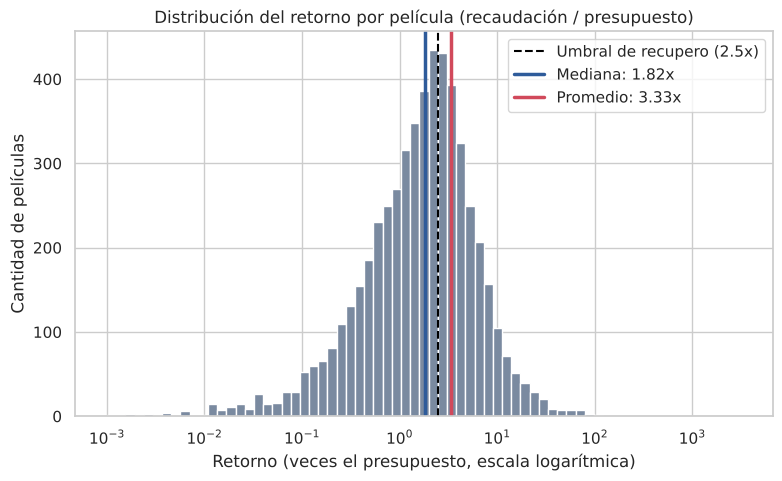

Películas con retorno menor al umbral: 61.3%
Películas por encima del promedio    : 28.3%


In [31]:
figura, eje = plt.subplots(figsize=(9, 5))
bordes = np.logspace(-3, 3.5, 70)
eje.hist(analisis["roi"], bins=bordes, color="#7a8aa0", edgecolor="white")
eje.set_xscale("log")
media_total, mediana_total = analisis["roi"].mean(), analisis["roi"].median()
eje.axvline(
    UMBRAL_RECUPERO, color="black", linestyle="--", label=f"Umbral de recupero ({UMBRAL_RECUPERO}x)"
)
eje.axvline(mediana_total, color="#2e5b9a", linewidth=2.5, label=f"Mediana: {mediana_total:.2f}x")
eje.axvline(media_total, color="#d1495b", linewidth=2.5, label=f"Promedio: {media_total:.2f}x")
eje.set_title("Distribución del retorno por película (recaudación / presupuesto)")
eje.set_xlabel("Retorno (veces el presupuesto, escala logarítmica)")
eje.set_ylabel("Cantidad de películas")
eje.legend()
guardar_figura(figura, "03_distribucion_retorno")
plt.show()
print(f"Películas con retorno menor al umbral: {(analisis['roi'] < UMBRAL_RECUPERO).mean():.1%}")
print(f"Películas por encima del promedio    : {(analisis['roi'] > media_total).mean():.1%}")

**Conclusión.** El promedio (3,33x) es un número que el 72% de las películas no alcanza: solo el 28,3% lo supera. La mediana (1,82x) está por debajo del umbral de recupero, y el 61,3% de las películas no llega a 2,5x.
El promedio lo sostiene una cola derecha de pocas películas con retornos de 50x o más. Decidir con el promedio significaría esperar un rendimiento que casi nadie obtiene.

<h3 style='font-weight:bold; color:#0033BB;'>4.3 Comparación entre géneros, ordenada por valor</h3>

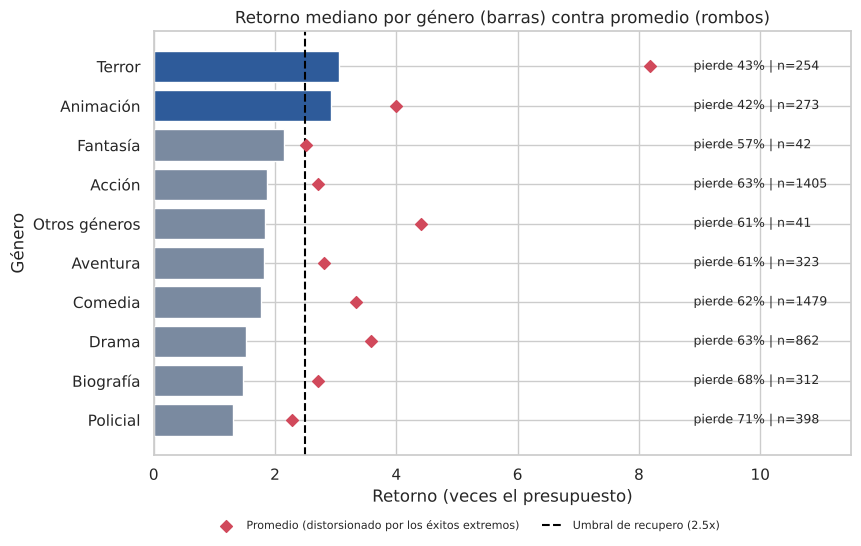

In [32]:
orden = por_genero.sort_values("retorno_mediano")
figura, eje = plt.subplots(figsize=(9, 5.5))
colores = [
    "#2e5b9a" if valor >= UMBRAL_RECUPERO else "#7a8aa0" for valor in orden["retorno_mediano"]
]
eje.barh(orden.index, orden["retorno_mediano"], color=colores)
eje.scatter(
    orden["retorno_medio"],
    orden.index,
    color="#d1495b",
    marker="D",
    zorder=3,
    label="Promedio (distorsionado por los éxitos extremos)",
)
eje.axvline(
    UMBRAL_RECUPERO, color="black", linestyle="--", label=f"Umbral de recupero ({UMBRAL_RECUPERO}x)"
)
for posicion, (_, fila) in enumerate(orden.iterrows()):
    eje.text(
        8.9,
        posicion,
        f"pierde {fila['p_perder']:.0%} | n={int(fila['n'])}",
        va="center",
        fontsize=9,
    )
eje.set_xlim(0, 11.5)
eje.set_title("Retorno mediano por género (barras) contra promedio (rombos)")
eje.set_xlabel("Retorno (veces el presupuesto)")
eje.set_ylabel("Género")
eje.legend(loc="upper center", bbox_to_anchor=(0.45, -0.13), ncol=2, fontsize=8, frameon=False)
guardar_figura(figura, "04_retorno_por_genero")
plt.show()

**Conclusión.** Solo Terror (3,05x) y Animación (2,92x) tienen una mediana por encima del umbral de recupero, y aun así pierden en 43% y 42% de los casos. El resto de los géneros pierde en entre 57% y 71%.
El promedio (rombos) exagera sobre todo a Terror, que casi triplica su mediana: 8,2x contra 3,05x. El orden por mediana y el orden por promedio no coinciden, y el que sirve para decidir es el primero.

<h3 style='font-weight:bold; color:#0033BB;'>4.4 Presupuesto contra recaudación, sin superposición de puntos</h3>

Con más de 5.000 puntos, un gráfico de dispersión se vuelve una mancha. Se resuelve con transparencia (cada punto es casi invisible, y donde se acumulan se oscurece) y con escala logarítmica en los dos ejes, que abre la zona de películas baratas.

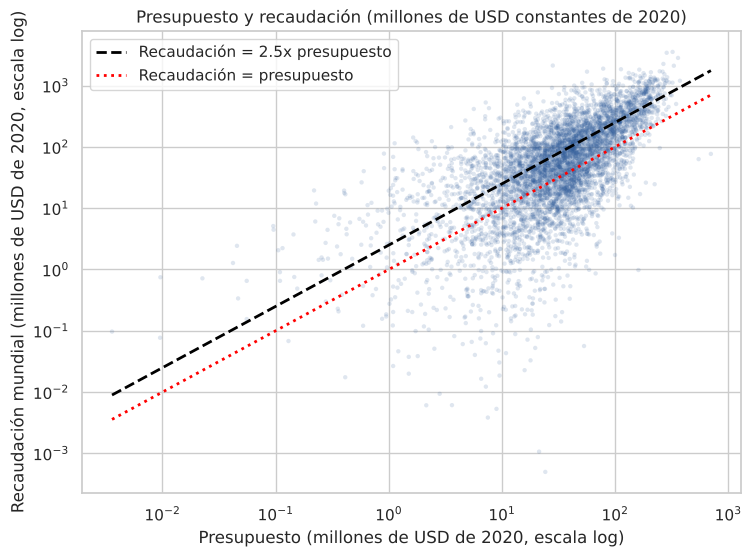

Correlación entre el log del presupuesto y el log de la recaudación: 0.63
Correlación entre el log del presupuesto y el log del retorno      : -0.03


In [33]:
figura, eje = plt.subplots(figsize=(8.5, 6))
eje.scatter(
    analisis["presupuesto_real"] / 1e6,
    analisis["recaudacion_real"] / 1e6,
    s=10,
    alpha=0.15,
    color="#2e5b9a",
    edgecolor="none",
)
minimo, maximo = analisis["presupuesto_real"].min() / 1e6, analisis["presupuesto_real"].max() / 1e6
recta = np.array([minimo, maximo])
eje.plot(
    recta,
    recta * UMBRAL_RECUPERO,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Recaudación = {UMBRAL_RECUPERO}x presupuesto",
)
eje.plot(recta, recta, color="red", linestyle=":", linewidth=2, label="Recaudación = presupuesto")
eje.set_xscale("log")
eje.set_yscale("log")
eje.set_title("Presupuesto y recaudación (millones de USD constantes de 2020)")
eje.set_xlabel("Presupuesto (millones de USD de 2020, escala log)")
eje.set_ylabel("Recaudación mundial (millones de USD de 2020, escala log)")
eje.legend(loc="upper left")
guardar_figura(figura, "05_presupuesto_vs_recaudacion")
plt.show()
print(
    f"Correlación entre el log del presupuesto y el log de la recaudación: {matriz.loc['Presupuesto (log)', 'Recaudación (log)']:.2f}"
)
print(
    f"Correlación entre el log del presupuesto y el log del retorno      : {matriz.loc['Presupuesto (log)', 'Retorno (log)']:.2f}"
)

**Conclusión.** Presupuesto y recaudación están asociados (correlación de 0,63 entre sus logaritmos), pero la mayor parte de las películas se agrupa entre la línea roja (recaudar lo mismo que se gastó) y la línea negra (el 2,5x), o apenas por encima de esta última, y el 61% queda por debajo de la negra:
muchas películas cubren su presupuesto con la boletería y aun así pierden plata según la regla de la industria. Gastar más presupuesto sube la recaudación pero no el múltiplo (correlación entre presupuesto y retorno: -0,03).

<h3 style='font-weight:bold; color:#0033BB;'>4.5 Gráfico interactivo (Plotly): el plano de riesgo y retorno</h3>

Cada burbuja es un segmento (género, tramo de presupuesto, clasificación, franquicia, productora, década u origen). Pasando el mouse se ve el detalle. La línea une los segmentos no dominados.

In [34]:
frontera = segmentos[segmentos["en_frontera"]].sort_values("p_perder")
figura_plotly = px.scatter(
    segmentos,
    x="p_perder",
    y="retorno_mediano",
    size="n",
    color="familia",
    hover_name="etiqueta",
    hover_data={
        "n": True,
        "p_perder": ":.1%",
        "retorno_mediano": ":.2f",
        "peor_decil": ":.2f",
        "familia": False,
    },
    labels={
        "p_perder": "Probabilidad de perder plata (retorno menor a 2,5x)",
        "retorno_mediano": "Retorno mediano (veces el presupuesto)",
        "familia": "Familia de segmentos",
        "n": "Películas",
        "peor_decil": "Retorno del peor decil",
    },
    title="Riesgo y retorno por segmento: arriba a la izquierda es mejor",
    size_max=34,
    height=620,
)
figura_plotly.add_trace(
    go.Scatter(
        x=frontera["p_perder"],
        y=frontera["retorno_mediano"],
        mode="lines",
        line=dict(color="black", dash="dot"),
        name="Frontera (no dominados)",
        hoverinfo="skip",
    )
)
figura_plotly.add_hline(
    y=UMBRAL_RECUPERO, line_dash="dash", line_color="grey", annotation_text="Umbral 2,5x"
)
figura_plotly.update_xaxes(tickformat=".0%")
figura_plotly.write_html(
    CARPETA_SALIDAS / "06_riesgo_retorno_interactivo.html", include_plotlyjs="cdn"
)
figura_plotly.show()

**Conclusión.** En el plano de riesgo y retorno solo cuatro segmentos forman la frontera. El de menor probabilidad de pérdida es Franquicia (41%, con mediana de 2,97x),
y el de mayor mediana (menos de 5 M, 3,34x) es también el más expuesto al sesgo de los faltantes. Todo lo que está abajo a la derecha (Policial, década de 1990, Miramax, Castle Rock) ofrece menos retorno con más riesgo.

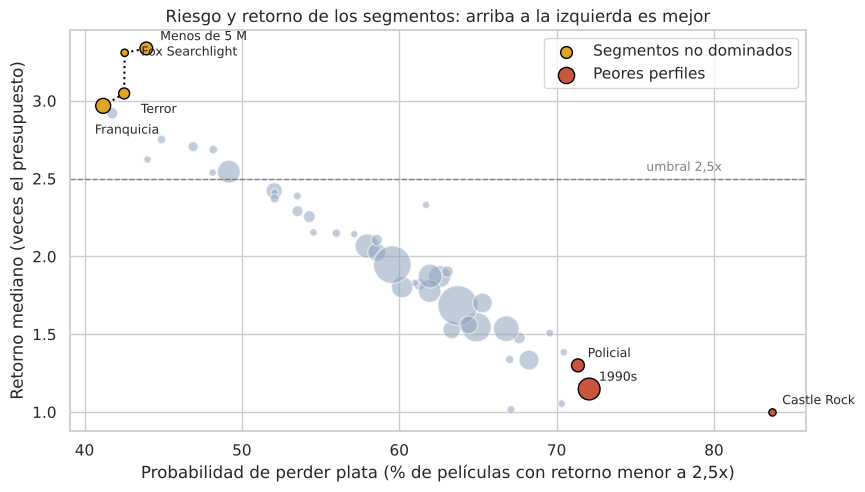

In [35]:
# Versión estática del mismo plano, para la presentación (el gráfico interactivo no entra en una diapositiva)
peores = segmentos.sort_values(["dominado_por", "retorno_mediano"], ascending=[False, True]).head(3)
figura, eje = plt.subplots(figsize=(9.5, 5.2))
eje.scatter(
    segmentos["p_perder"] * 100,
    segmentos["retorno_mediano"],
    s=segmentos["n"] / 6 + 20,
    color="#8fa3bf",
    alpha=0.55,
    edgecolor="white",
)
eje.scatter(
    frontera["p_perder"] * 100,
    frontera["retorno_mediano"],
    s=frontera["n"] / 6 + 20,
    color="#e0a526",
    edgecolor="black",
    zorder=3,
    label="Segmentos no dominados",
)
eje.plot(
    frontera["p_perder"] * 100, frontera["retorno_mediano"], color="black", linestyle=":", zorder=2
)
eje.scatter(
    peores["p_perder"] * 100,
    peores["retorno_mediano"],
    s=peores["n"] / 6 + 20,
    color="#c8553d",
    edgecolor="black",
    zorder=3,
    label="Peores perfiles",
)
# Desplazamientos manuales (en puntos) para que las etiquetas de la esquina superior no se pisen
DESPLAZAMIENTO_ETIQUETAS = {
    "Menos de 5 M": (10, 6),
    "Fox Searchlight": (12, -2),
    "Terror": (12, -14),
    "Franquicia": (-6, -20),
}
for _, fila in pd.concat([frontera, peores]).iterrows():
    nombre = fila["etiqueta"].split(": ")[1].replace(" Pictures", "").replace(" Entertainment", "")
    desplazamiento = DESPLAZAMIENTO_ETIQUETAS.get(nombre, (7, 6))
    eje.annotate(
        nombre,
        (fila["p_perder"] * 100, fila["retorno_mediano"]),
        textcoords="offset points",
        xytext=desplazamiento,
        fontsize=9,
    )
eje.axhline(UMBRAL_RECUPERO, color="grey", linestyle="--", linewidth=1)
eje.text(80.5, UMBRAL_RECUPERO + 0.05, "umbral 2,5x", color="grey", fontsize=9, ha="right")
eje.set_title("Riesgo y retorno de los segmentos: arriba a la izquierda es mejor")
eje.set_xlabel("Probabilidad de perder plata (% de películas con retorno menor a 2,5x)")
eje.set_ylabel("Retorno mediano (veces el presupuesto)")
eje.legend(loc="upper right")
guardar_figura(figura, "08_plano_riesgo_retorno")
plt.show()

<h2 style='font-weight:bold; color:#003366;'>Etapa 5: La tesis de inversión</h2>

<h3 style='font-weight:bold; color:#0033BB;'>5.1 Los grupos de películas (arquetipos)</h3>

Se definen cinco grupos con criterios que se pueden verificar en los datos (género, franquicia, presupuesto en dólares constantes).
Se aplican en orden de prioridad con `if` y `elif` (una película cae en el primero que cumple), de modo que los grupos no se superponen.
Los umbrales son redondos a propósito (50, 30 y 80 millones) para no ajustarlos al dato. Las métricas que justifican cada grupo y la cantidad de proyectos se calculan solo con películas hasta 2014.
Una advertencia de honestidad: la sección 3 exploró toda la muestra, así que la prueba de la sección 5.5 es una verificación de estabilidad y no una prueba totalmente independiente.

In [36]:
ARQUETIPOS = [
    "A. Franquicia grande",
    "B. Animación",
    "C. Terror contenido",
    "D. Acción o aventura grande sin franquicia",
    "E. Resto del mercado",
]
GENEROS_TENTPOLE = ["Acción", "Aventura", "Fantasía", "Ciencia ficción"]
PRESUPUESTO_FRANQUICIA_GRANDE = 50e6  # USD de 2020
PRESUPUESTO_TERROR_MAXIMO = 30e6
PRESUPUESTO_TENTPOLE_MINIMO = 80e6


def asignar_arquetipo(pelicula):
    """Asigna la película al primer arquetipo cuyo criterio cumple (orden de prioridad)."""
    if pelicula["es_secuela"] and pelicula["presupuesto_real"] >= PRESUPUESTO_FRANQUICIA_GRANDE:
        return ARQUETIPOS[0]
    elif pelicula["genero"] == "Animación":
        return ARQUETIPOS[1]
    elif (
        pelicula["genero"] == "Terror" and pelicula["presupuesto_real"] < PRESUPUESTO_TERROR_MAXIMO
    ):
        return ARQUETIPOS[2]
    elif (
        pelicula["genero"] in GENEROS_TENTPOLE
        and pelicula["presupuesto_real"] >= PRESUPUESTO_TENTPOLE_MINIMO
    ):
        return ARQUETIPOS[3]
    return ARQUETIPOS[4]


analisis["arquetipo"] = analisis.apply(asignar_arquetipo, axis=1)
base_imputada["arquetipo"] = base_imputada.apply(asignar_arquetipo, axis=1)
entrenamiento = analisis[analisis["anio_estreno"] <= ANIO_CORTE].copy()
prueba = analisis[analisis["anio_estreno"] > ANIO_CORTE].copy()
entrenamiento_imputado = base_imputada[base_imputada["anio_estreno"] <= ANIO_CORTE]
prueba_imputada = base_imputada[base_imputada["anio_estreno"] > ANIO_CORTE]
print(
    f"Películas de entrenamiento (hasta {ANIO_CORTE}): {len(entrenamiento):,} | de prueba (2015-2020): {len(prueba):,}"
)


def tabla_arquetipos(df, df_imputada):
    """Métricas de riesgo y retorno por arquetipo, más el presupuesto típico (mediana en USD M de 2020)."""
    tabla = metricas_con_escenario(df, df_imputada, "arquetipo").reindex(ARQUETIPOS)
    tabla["presupuesto_tipico_M"] = (
        df.groupby("arquetipo")["presupuesto_real"].median().reindex(ARQUETIPOS) / 1e6
    )
    return tabla


tabla_entrenamiento = tabla_arquetipos(entrenamiento, entrenamiento_imputado)
print("ENTRENAMIENTO (hasta 2014). Los criterios y la asignación salen de esta tabla:")
display(tabla_entrenamiento)

Películas de entrenamiento (hasta 2014): 4,683 | de prueba (2015-2020): 706
ENTRENAMIENTO (hasta 2014). Los criterios y la asignación salen de esta tabla:


,n,retorno_medio,retorno_mediano,p_perder,peor_decil,retorno_mediano_imputado,p_perder_imputada,presupuesto_tipico_M
arquetipo,,,,,,,,
A. Franquicia grande,226,3.77,2.92,0.41,0.92,2.89,0.42,102.50
B. Animación,183,3.73,2.76,0.48,0.49,2.09,0.56,68.50
C. Terror contenido,177,9.16,3.14,0.40,0.36,2.51,0.49,10.82
D. Acción o aventura grande sin franquicia,374,2.37,1.96,0.63,0.51,1.96,0.63,120.75
E. Resto del mercado,3723,2.93,1.51,0.67,0.21,0.98,0.76,29.15


**Lectura (solo entrenamiento, hasta 2014).** Tres grupos se separan del resto:

- **A. Franquicia grande** (secuelas de 50 M o más): mediana 2,92x, pierde en 41%, el mejor peor decil (0,92x: el 90% de estas películas recauda al menos 0,92 veces lo que costó). Presupuesto típico USD 102,5 M.
- **B. Animación**: mediana 2,76x, pierde en 48%, presupuesto típico 68,5 M.
- **C. Terror contenido** (menos de 30 M): mediana 3,14x, pierde en 40%, presupuesto típico 10,8 M, pero con el peor decil bajo (0,36x).

Contra eso, D. Acción o aventura grande sin franquicia (1,96x, pierde 63%, presupuesto típico 120,8 M) y E. el resto (1,51x, pierde 67%) no llegan al umbral. Con presupuestos imputados, las medianas son 2,89x, 2,09x y 2,51x para A, B y C, y 1,96x y 0,98x para D y E:
el orden se mantiene.

Un dato incómodo: incluso en los mejores grupos, entre 40% y 56% de las películas individuales no recuperan. Un proyecto aislado es casi una moneda al aire; lo que tiene valor es el portafolio.

**¿Los arquetipos dependen de pocos éxitos extremos o de un par de décadas?** Dos controles antes de confiar en ellos.

In [37]:
concentracion_arq = (
    entrenamiento.groupby("arquetipo")["roi"].agg(concentracion_top).reindex(ARQUETIPOS)
)
estabilidad = (
    entrenamiento.groupby(["arquetipo", "decada"])["roi"].median().unstack().reindex(ARQUETIPOS)
)
control = pd.DataFrame(
    {
        "fraccion_retorno_en_top5": concentracion_arq,
        "mejor_decada_sobre_peor": estabilidad.max(axis=1) / estabilidad.min(axis=1),
    }
)
display(control)
print("Retorno mediano por década (¿es estable o vive de una época?):")
display(estabilidad[["1980s", "1990s", "2000s", "2010s"]])

,fraccion_retorno_en_top5,mejor_decada_sobre_peor
arquetipo,,
A. Franquicia grande,0.10,1.53
B. Animación,0.18,1.81
C. Terror contenido,0.26,4.19
D. Acción o aventura grande sin franquicia,0.07,2.93
E. Resto del mercado,0.03,2.21


Retorno mediano por década (¿es estable o vive de una época?):


decada,1980s,1990s,2000s,2010s
arquetipo,,,,
A. Franquicia grande,3.00,2.43,2.66,3.71
B. Animación,2.58,1.64,2.40,2.96
C. Terror contenido,3.31,2.00,3.21,8.38
D. Acción o aventura grande sin franquicia,0.77,1.95,1.87,2.27
E. Resto del mercado,1.48,1.00,1.66,2.21


**Lectura.** Franquicias es el grupo más estable: su mejor década es solo 1,5 veces su peor (retorno mediano entre 2,43x y 3,71x), y las 5 mejores películas explican apenas el 10% del retorno total.
Terror contenido es el opuesto: la mejor década es 4,2 veces la peor (2,00x en los 90 contra 8,38x en los 2010) y el 26% del retorno total lo explican 5 películas. Su resultado depende de una época y de unos pocos éxitos.
Animación tiene una amplitud intermedia (1,8 veces). Esto condiciona cuánto se puede apostar a cada grupo.

<h3 style='font-weight:bold; color:#0033BB;'>5.2 Asignación de los USD 500 millones</h3>

La cantidad de proyectos sale de dividir el capital de cada grupo por su presupuesto típico (mediana en dólares de 2020 de las películas de entrenamiento).
Es la verificación de coherencia que pide la letra: si el grupo tiene presupuesto típico de 100 M, no se pueden hacer 10 proyectos con 100 M.
**Sobre la reserva de USD 50 M (10%).** Es una decisión de diseño y no sale de los datos. La letra pide asignar los USD 500 M, y los 450 M restantes quedan comprometidos en 14 proyectos;
los otros 50 M no se asignan a ninguna película en particular. Las razones: (1) los presupuestos de la base son de producción y no incluyen marketing ni distribución, y las películas suelen pasarse de presupuesto,
así que sin colchón un sobrecosto obligaría a recortar otro proyecto; (2) el fondo coloca la plata a lo largo de tres años y no hace falta comprometerlo todo el primer día; (3) si no se usa, vuelve al fondo y no es una pérdida.
Los retornos de la sección 5.3 se calculan sobre los 450 M invertidos: la reserva no genera retorno.

In [38]:
PROYECTOS_ELEGIDOS = {"A. Franquicia grande": 2, "B. Animación": 2, "C. Terror contenido": 10}

presupuesto_tipico = entrenamiento.groupby("arquetipo")["presupuesto_real"].median()
rango_p25 = entrenamiento.groupby("arquetipo")["presupuesto_real"].quantile(0.25)
rango_p75 = entrenamiento.groupby("arquetipo")["presupuesto_real"].quantile(0.75)

asignacion = pd.DataFrame(
    {
        "proyectos": pd.Series(PROYECTOS_ELEGIDOS),
        "presupuesto_tipico_M": presupuesto_tipico.reindex(list(PROYECTOS_ELEGIDOS)) / 1e6,
        "rango_p25_p75_M": pd.Series(
            {a: f"{rango_p25[a] / 1e6:.0f} a {rango_p75[a] / 1e6:.0f}" for a in PROYECTOS_ELEGIDOS}
        ),
    }
)
asignacion["capital_M"] = asignacion["proyectos"] * asignacion["presupuesto_tipico_M"]
asignacion["pct_del_fondo"] = asignacion["capital_M"] / (PRESUPUESTO_FONDO / 1e6) * 100
capital_invertido = asignacion["capital_M"].sum()
reserva = PRESUPUESTO_FONDO / 1e6 - capital_invertido
display(asignacion)
print(
    f"Capital asignado a proyectos: USD {capital_invertido:,.0f} M ({capital_invertido / (PRESUPUESTO_FONDO / 1e6):.0%}) | reserva: USD {reserva:,.0f} M"
)
print(
    f"Proyectos totales: {int(asignacion['proyectos'].sum())} en tres años (unos {asignacion['proyectos'].sum() / 3:.1f} por año)"
)
asignacion.to_csv(CARPETA_SALIDAS / "asignacion_fondo.csv")

,proyectos,presupuesto_tipico_M,rango_p25_p75_M,capital_M,pct_del_fondo
A. Franquicia grande,2,102.50,70 a 165,204.99,41.00
B. Animación,2,68.50,36 a 135,137.00,27.40
C. Terror contenido,10,10.82,5 a 19,108.18,21.64


Capital asignado a proyectos: USD 450 M (90%) | reserva: USD 50 M
Proyectos totales: 14 en tres años (unos 4.7 por año)


**Lectura.** La asignación propuesta es de 14 proyectos (unos 4,7 por año):

- **2 franquicias grandes** por USD 205 M (41% del fondo). Presupuesto típico 102,5 M y rango intercuartil de 70 a 165 M.
- **2 animaciones** por USD 137 M (27,4%). Típico 68,5 M, rango de 36 a 135 M.
- **10 películas de terror contenido** por USD 108 M (21,6%). Típico 10,8 M, rango de 5 a 19 M.
- **Reserva de USD 50 M (10%)** para sobrecostos, que no se asigna a ninguna película en particular.

La cantidad de proyectos es coherente con el presupuesto típico de cada grupo: se compran pocas películas caras y varias baratas, no al revés. Los presupuestos históricos son de producción (no incluyen marketing ni distribución).
El costo de la propuesta es que las franquicias y la animación son piezas grandes (con solo 2 proyectos de cada una, un fracaso pesa mucho), y que la franquicia exige acceso a los derechos (la tesis supone coinversión con un estudio dueño de la propiedad).
El 10% de reserva es una decisión de diseño y no sale de los datos.

<h3 style='font-weight:bold; color:#0033BB;'>5.3 Retorno esperado y riesgo de perder capital</h3>

No se usa el promedio: se usan medianas, como pide la letra. El fondo coloca la plata a lo largo de tres años, así que la pregunta natural es:
*si hubiéramos armado este portafolio en cualquier ventana de tres años de la historia, ¿cómo nos habría ido?*

Para cada ventana de tres años (1980-82, 1981-83, y así hasta la última que termina en 2014) se calcula la mediana del retorno de cada arquetipo con las películas estrenadas en esa ventana,
y el retorno del portafolio es el promedio de esas medianas ponderado por el capital de cada arquetipo. De ahí salen:

- el retorno esperado: la mediana de todas las ventanas;
- la frecuencia de ventanas desfavorables, que usamos como aproximación al riesgo de perder capital: el porcentaje de ventanas en que el portafolio no llega al umbral de 2,5× (y también al estricto de 3,5×). No es la probabilidad exacta de que estas 14 películas pierdan plata, porque con medianas por arquetipo no se captura cuánto pueden diferir las películas entre sí;
- el peor caso: la peor ventana.

Se hace en dos versiones: con las películas que tienen presupuesto (observado) y con el escenario de presupuestos imputados. Hay dos preguntas distintas y conviene no confundirlas: *¿la película recuperó según la regla de la industria?* (recaudación de 2,5 veces el presupuesto o más, que es la regla de la letra) y *¿el estudio cubrió todos sus costos?*
(para eso el equilibrio es 3,5x, porque el exhibidor se queda con la mitad de la boletería y el marketing suma otro 75% del presupuesto). Entre 2,5x y 3,5x una película "recupera" según la industria pero igual pierde plata si se cuenta la parte del exhibidor y el marketing.
Por eso las dos frecuencias son tan distintas, y no se contradicen: responden preguntas diferentes.

Las ventanas se superponen (la de 1980-82 comparte dos años con la de 1981-83), así que son unas 11 ventanas realmente distintas y no 33: hay que leerlo como una frecuencia histórica y no como una probabilidad exacta.

In [39]:
def mediana_en_ventana(df, inicio, arquetipo):
    """Mediana del retorno de un arquetipo (o de todo el mercado) en una ventana de VENTANA_ANIOS años."""
    ventana = df[(df["anio_estreno"] >= inicio) & (df["anio_estreno"] < inicio + VENTANA_ANIOS)]
    if arquetipo != "Mercado":
        ventana = ventana[ventana["arquetipo"] == arquetipo]
    if len(ventana) < MIN_VENTANA:
        return np.nan
    return ventana["roi"].median()


def retorno_portafolio(df, inicio, capitales):
    """Retorno del portafolio en una ventana: promedio de las medianas de cada arquetipo ponderado por su capital."""
    total = 0
    for arquetipo, capital in capitales.items():
        mediana = mediana_en_ventana(df, inicio, arquetipo)
        if np.isnan(mediana):
            return np.nan
        total += capital * mediana
    return total / sum(capitales.values())


def margen_neto(multiplo):
    """Margen estimado sobre el costo total (producción + marketing) para un retorno bruto dado.

    El estudio se queda con PARTE_ESTUDIO de la boletería y gasta (1 + marketing) veces el presupuesto.
    """
    costo_total = 1 + MARKETING_SOBRE_PRESUPUESTO
    return (PARTE_ESTUDIO * multiplo - costo_total) / costo_total


def serie_ventanas(df, capitales, inicios):
    """Retorno del portafolio en cada ventana (una fila por año de inicio)."""
    return pd.Series(
        {inicio: retorno_portafolio(df, inicio, capitales) for inicio in inicios}
    ).dropna()


def resumir_ventanas(serie):
    """Retorno esperado, peor caso y frecuencia de ventanas por debajo de los umbrales."""
    return {
        "ventanas": len(serie),
        "retorno_mediano": serie.median(),
        "margen_neto_mediano": margen_neto(serie.median()),
        "peor_ventana": serie.min(),
        "pct_ventanas_menor_2_5x": (serie < UMBRAL_RECUPERO).mean() * 100,
        "pct_ventanas_menor_3_5x": (serie < UMBRAL_ESTRICTO).mean() * 100,
    }


INICIOS_ENTRENAMIENTO = range(
    1980, ANIO_CORTE - VENTANA_ANIOS + 2
)  # ventanas que terminan en 2014 o antes
INICIOS_PRUEBA = range(ANIO_CORTE + 1, 2019)  # ventanas dentro de 2015-2020
capitales_elegidos = asignacion["capital_M"].to_dict()

serie_observada = serie_ventanas(analisis, capitales_elegidos, INICIOS_ENTRENAMIENTO)
serie_imputada = serie_ventanas(base_imputada, capitales_elegidos, INICIOS_ENTRENAMIENTO)
resumen_elegido = pd.DataFrame(
    {
        "Observado": resumir_ventanas(serie_observada),
        "Presupuestos imputados": resumir_ventanas(serie_imputada),
    }
).T
display(resumen_elegido)

# Riesgo de un proyecto individual dentro de cada arquetipo (lo que se pierde si sale mal una sola película)
riesgo_proyecto = tabla_entrenamiento.loc[list(PROYECTOS_ELEGIDOS), "p_perder"]
riesgo_ponderado = (riesgo_proyecto * asignacion["capital_M"]).sum() / asignacion["capital_M"].sum()
print(
    f"Probabilidad de que un proyecto individual del portafolio no recupere (ponderada por capital): {riesgo_ponderado:.0%}"
)
print(
    f"Peor ventana: el portafolio habría rendido {serie_observada.min():.2f}x, "
    f"{max(0, 1 - serie_observada.min() / UMBRAL_RECUPERO):.0%} por debajo del equilibrio de la industria"
)
print(
    "Ventanas donde el portafolio no llegó a 2,5x (observado):",
    [
        f"{inicio}-{inicio + 2}"
        for inicio in serie_observada[serie_observada < UMBRAL_RECUPERO].index
    ],
)

,ventanas,retorno_mediano,margen_neto_mediano,peor_ventana,pct_ventanas_menor_2_5x,pct_ventanas_menor_3_5x
Observado,31.00,2.71,-0.23,1.38,29.03,90.32
Presupuestos imputados,32.00,2.49,-0.29,1.20,53.12,93.75


Probabilidad de que un proyecto individual del portafolio no recupere (ponderada por capital): 43%
Peor ventana: el portafolio habría rendido 1.38x, 45% por debajo del equilibrio de la industria
Ventanas donde el portafolio no llegó a 2,5x (observado): ['1982-1984', '1983-1985', '1989-1991', '1990-1992', '1991-1993', '1992-1994', '1993-1995', '1994-1996', '1997-1999']


**Lectura (portafolio propuesto, ventanas de tres años entre 1980 y 2014).**

- **Retorno esperado.** La mediana de las 31 ventanas es 2,71x el capital invertido (2,49x con presupuestos imputados), apenas por encima del umbral de recupero de 2,5x.
- **Ventanas desfavorables.** En el 29% de las ventanas (9 de 31) el portafolio no habría llegado a 2,5x; con presupuestos imputados, en el 53%. Se concentran entre fines de los 80 y los 90 (1989-91 a 1994-96) y en 1997-99.
  Es una frecuencia histórica y no la probabilidad exacta de que estas 14 películas pierdan plata: con medianas por arquetipo no se captura cuánto pueden diferir las películas entre sí.
- **Proyecto individual.** Lo más cercano a un riesgo por película es que el 43% de las películas del portafolio (ponderado por capital) no recupera.
- **Cuánto se puede perder.** La peor ventana habría rendido 1,38x, un 45% por debajo del equilibrio de 2,5x (1,20x con imputados).
- **Con el criterio estricto** (50% para el exhibidor y 75% de marketing), el equilibrio es 3,5x: el portafolio no lo alcanza en el 90% de las ventanas y el margen neto mediano estimado es de -23%. Son dos preguntas distintas: el 2,5x es la regla de la industria que usa la letra; el 3,5x es el equilibrio si se cuenta la parte del exhibidor y el marketing. El 29% y el 90% no se contradicen: entre 2,5x y 3,5x una película "recupera" según la industria pero el estudio igual pierde plata.

**Cómo leerlo.** Estas cifras son conservadoras a propósito: se usan medianas por arquetipo (como pide la letra), y un portafolio de 14 películas se acerca más al promedio que a la mediana, y el promedio es bastante más alto (la sección 3 muestra por qué es engañoso). Pero no se puede suponer un resultado mejor que el que muestran los datos.
La conclusión es más matizada que una cifra única: en la historia, el portafolio habría estado cerca del punto de equilibrio de la industria, con un riesgo no menor y lejos de cubrir el costo total con marketing.

<h3 style='font-weight:bold; color:#0033BB;'>5.4 ¿Por qué no poner todo en el segmento de mejor retorno?</h3>

In [40]:
def estrategia_todo_en(arquetipo):
    """Todo el fondo en un solo arquetipo."""
    return {arquetipo: PRESUPUESTO_FONDO / 1e6}


estrategias = {
    "Propuesta (A+B+C, 14 proyectos)": capitales_elegidos,
    "Todo en terror contenido": estrategia_todo_en("C. Terror contenido"),
    "Todo en franquicias grandes": estrategia_todo_en("A. Franquicia grande"),
    "Todo en animación": estrategia_todo_en("B. Animación"),
    "Todo en acción o aventura grande": estrategia_todo_en(
        "D. Acción o aventura grande sin franquicia"
    ),
    "Mercado: películas elegidas al azar": estrategia_todo_en("Mercado"),
}
proyectos_por_estrategia = {
    "Propuesta (A+B+C, 14 proyectos)": 14,
    "Todo en terror contenido": int(PRESUPUESTO_FONDO // presupuesto_tipico["C. Terror contenido"]),
    "Todo en franquicias grandes": int(
        PRESUPUESTO_FONDO // presupuesto_tipico["A. Franquicia grande"]
    ),
    "Todo en animación": int(PRESUPUESTO_FONDO // presupuesto_tipico["B. Animación"]),
    "Todo en acción o aventura grande": int(
        PRESUPUESTO_FONDO // presupuesto_tipico["D. Acción o aventura grande sin franquicia"]
    ),
    "Mercado: películas elegidas al azar": int(
        PRESUPUESTO_FONDO // analisis["presupuesto_real"].median()
    ),
}

filas = []
for nombre, capitales in estrategias.items():
    observado = resumir_ventanas(serie_ventanas(analisis, capitales, INICIOS_ENTRENAMIENTO))
    imputado = resumir_ventanas(serie_ventanas(base_imputada, capitales, INICIOS_ENTRENAMIENTO))
    filas.append(
        {
            "estrategia": nombre,
            "proyectos": proyectos_por_estrategia[nombre],
            "retorno_mediano": observado["retorno_mediano"],
            "peor_ventana": observado["peor_ventana"],
            "pct_ventanas_menor_2_5x": observado["pct_ventanas_menor_2_5x"],
            "pct_menor_2_5x_imputado": imputado["pct_ventanas_menor_2_5x"],
        }
    )
comparacion_estrategias = pd.DataFrame(filas).set_index("estrategia")
display(comparacion_estrategias)

peliculas_terror = int((entrenamiento["arquetipo"] == "C. Terror contenido").sum())
anios_entrenamiento = ANIO_CORTE - 1980 + 1
print(
    f"Terror contenido: {peliculas_terror} películas con presupuesto conocido en {anios_entrenamiento} años "
    f"(unas {peliculas_terror / anios_entrenamiento:.1f} por año en esta base, {VENTANA_ANIOS * peliculas_terror / anios_entrenamiento:.0f} en tres años)."
)
print(
    f"'Todo en terror' exigiría {proyectos_por_estrategia['Todo en terror contenido']} proyectos."
)

,proyectos,retorno_mediano,peor_ventana,pct_ventanas_menor_2_5x,pct_menor_2_5x_imputado
estrategia,,,,,
"Propuesta (A+B+C, 14 proyectos)",14,2.71,1.38,29.03,53.12
Todo en terror contenido,46,3.05,1.01,36.36,51.52
Todo en franquicias grandes,4,2.70,1.51,32.26,50.00
Todo en animación,7,2.51,0.51,50.00,72.73
Todo en acción o aventura grande,4,1.88,0.26,90.00,90.32
Mercado: películas elegidas al azar,14,1.68,1.07,96.97,100.00


Terror contenido: 177 películas con presupuesto conocido en 35 años (unas 5.1 por año en esta base, 15 en tres años).
'Todo en terror' exigiría 46 proyectos.


**Lectura.** El portafolio propuesto es la estrategia con menos ventanas por debajo de 2,5x entre las observadas (29%), contra 32% de "todo en franquicias", 36% de "todo en terror", 50% de "todo en animación" y 90% o más de acción o aventura grande y de elegir películas al azar del mercado (97%, con una mediana de ventanas de apenas 1,68x).
Con presupuestos imputados la ventaja de combinar se achica: 53% contra 50% y 52% de las estrategias de franquicia y terror solas, o sea que la ventaja de combinar es chica frente a concentrar en franquicias o en terror (en la peor ventana, 1,38x contra 1,51x de franquicias, 1,01x de terror y 0,51x de animación).

"Todo en terror contenido" tiene la mediana más alta de ventanas (3,05x), pero la tesis no lo hace, por cuatro razones:

1. **Capacidad.** Haría falta financiar 46 proyectos. En la base hay 5,1 películas de terror contenido por año, o sea unas 15 en tres años: se necesitarían tres veces todo el volumen de la base. Incluso los 10 proyectos propuestos son una porción grande y habrá que validar que existan.
2. **Dependencia de una época y de pocos éxitos.** La mejor década es 4,2 veces la peor (2,00x en los 90 contra 8,38x en los 2010) y 5 películas explican el 26% del retorno total. En una ventana mala, su retorno cae a 1,01x.
3. **Es el grupo con la estimación menos confiable.** Su mediana cae de 3,14x a 2,51x con presupuestos imputados y en la prueba tiene solo 30 películas. Además la base contiene solo películas que llegaron a estrenarse: los terrores baratos que nunca tuvieron distribución no están en los datos.
4. **Una sola apuesta.** Todo el fondo dependería de una sola idea.

En el otro extremo, concentrar todo en un grupo de pocos proyectos grandes también es riesgoso (franquicias: solo 4 proyectos; animación: 7).

<h3 style='font-weight:bold; color:#0033BB;'>5.5 ¿La tesis sobrevive fuera de muestra? (2015-2020)</h3>

Los criterios (arquetipos, presupuestos típicos, cantidad de proyectos) se construyeron solo con películas hasta 2014. Ahora se aplican, sin tocar nada,
a las 706 películas estrenadas entre 2015 y 2020 y se compara lo que la tesis esperaba con lo que pasó. Hay solo cuatro ventanas de tres años dentro de ese período (2015-17 hasta 2018-20).

entrenamiento                  \
                                                       n retorno_mediano   
arquetipo                                                                  
A. Franquicia grande                                 226            2.92   
B. Animación                                         183            2.76   
C. Terror contenido                                  177            3.14   
D. Acción o aventura grande sin franquicia           374            1.96   
E. Resto del mercado                                3723            1.51   

                                                               prueba  \
                                           p_perder peor_decil      n   
arquetipo                                                               
A. Franquicia grande                           0.41       0.92     74   
B. Animación                                   0.48       0.49     45   
C. Terror contenido                            0.40       0.36     30   
D. Acción o aventura grande sin franquicia     0.63       0.51     81   
E. Resto del mercado                           0.67       0.21    476   

                                                                                
                                           retorno_mediano p_perder peor_decil  
arquetipo                                                                       
A. Franquicia grande                                  3.84     0.23       1.86  
B. Animación                                          3.30     0.33       0.71  
C. Terror contenido                                   6.80     0.23       0.56  
D. Acción o aventura grande sin franquicia            2.31     0.53       1.04  
E. Resto del mercado                                  2.33     0.53       0.42

Portafolio propuesto, ventanas de 2015-2020:


,ventanas,retorno_mediano,margen_neto_mediano,peor_ventana,pct_ventanas_menor_2_5x,pct_ventanas_menor_3_5x
Observado,4.00,4.60,0.31,4.19,0.00,0.00
Presupuestos imputados,4.00,3.76,0.07,3.34,0.00,25.00


Mercado al azar: mediana de ventanas 1.68x hasta 2014 y 2.86x en 2015-2020
Retorno del portafolio por ventana, 2015-2020: {'2015-2017': 4.21, '2016-2018': 4.19, '2017-2019': 5.92, '2018-2020': 4.99}


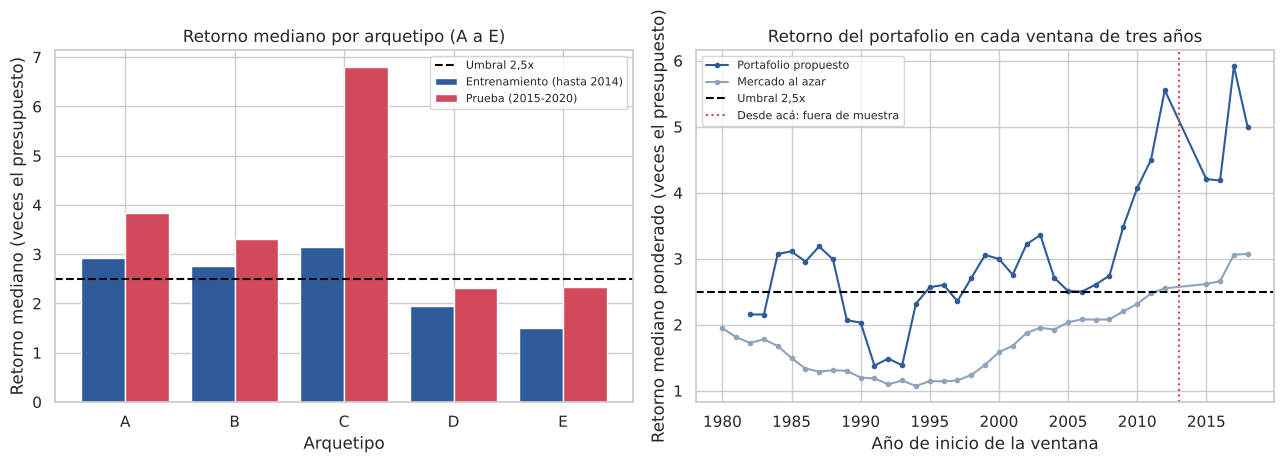

In [41]:
tabla_prueba = tabla_arquetipos(prueba, prueba_imputada)
comparacion_periodos = pd.concat(
    {
        "entrenamiento": tabla_entrenamiento[["n", "retorno_mediano", "p_perder", "peor_decil"]],
        "prueba": tabla_prueba[["n", "retorno_mediano", "p_perder", "peor_decil"]],
    },
    axis=1,
)
display(comparacion_periodos)

# El MISMO portafolio, ventana por ventana, en 2015-2020
serie_prueba_observada = serie_ventanas(analisis, capitales_elegidos, INICIOS_PRUEBA)
serie_prueba_imputada = serie_ventanas(base_imputada, capitales_elegidos, INICIOS_PRUEBA)
resumen_prueba = pd.DataFrame(
    {
        "Observado": resumir_ventanas(serie_prueba_observada),
        "Presupuestos imputados": resumir_ventanas(serie_prueba_imputada),
    }
).T
print("Portafolio propuesto, ventanas de 2015-2020:")
display(resumen_prueba)

# Referencia: el mercado elegido al azar en las mismas ventanas
mercado_entrenamiento = serie_ventanas(analisis, {"Mercado": 1}, INICIOS_ENTRENAMIENTO)
mercado_prueba = serie_ventanas(analisis, {"Mercado": 1}, INICIOS_PRUEBA)
print(
    f"Mercado al azar: mediana de ventanas {mercado_entrenamiento.median():.2f}x hasta 2014 y {mercado_prueba.median():.2f}x en 2015-2020"
)
print(
    "Retorno del portafolio por ventana, 2015-2020:",
    {f"{i}-{i + 2}": round(v, 2) for i, v in serie_prueba_observada.items()},
)

figura, ejes = plt.subplots(1, 2, figsize=(13, 4.6))
posiciones = np.arange(len(ARQUETIPOS))
ejes[0].bar(
    posiciones - 0.2,
    tabla_entrenamiento["retorno_mediano"],
    0.4,
    label="Entrenamiento (hasta 2014)",
    color="#2e5b9a",
)
ejes[0].bar(
    posiciones + 0.2,
    tabla_prueba["retorno_mediano"],
    0.4,
    label="Prueba (2015-2020)",
    color="#d1495b",
)
ejes[0].axhline(UMBRAL_RECUPERO, color="black", linestyle="--", label="Umbral 2,5x")
ejes[0].set_xticks(posiciones, [a.split(".")[0] for a in ARQUETIPOS])
ejes[0].set_title("Retorno mediano por arquetipo (A a E)")
ejes[0].set_xlabel("Arquetipo")
ejes[0].set_ylabel("Retorno mediano (veces el presupuesto)")
ejes[0].legend(fontsize=8)
todas_ventanas = pd.concat([serie_observada, serie_prueba_observada])
mercado_todas = pd.concat([mercado_entrenamiento, mercado_prueba])
ejes[1].plot(
    todas_ventanas.index,
    todas_ventanas.values,
    color="#2e5b9a",
    marker="o",
    markersize=3,
    label="Portafolio propuesto",
)
ejes[1].plot(
    mercado_todas.index,
    mercado_todas.values,
    color="#8fa3bf",
    marker="o",
    markersize=3,
    label="Mercado al azar",
)
ejes[1].axhline(UMBRAL_RECUPERO, color="black", linestyle="--", label="Umbral 2,5x")
ejes[1].axvline(ANIO_CORTE - 1, color="#d1495b", linestyle=":", label="Desde acá: fuera de muestra")
ejes[1].set_title("Retorno del portafolio en cada ventana de tres años")
ejes[1].set_xlabel("Año de inicio de la ventana")
ejes[1].set_ylabel("Retorno mediano ponderado (veces el presupuesto)")
ejes[1].legend(fontsize=8)
plt.tight_layout()
guardar_figura(figura, "07_fuera_de_muestra")
plt.show()

**Lectura.** Con los criterios construidos hasta 2014, el orden se sostiene en 2015-2020: los tres arquetipos elegidos siguen mejor que el resto.

| Arquetipo | Mediana 2014- | Mediana 2015-20 | Pierde 2014- | Pierde 2015-20 |
|---|---|---|---|---|
| A. Franquicia grande | 2,92x | 3,84x | 41% | 23% |
| B. Animación | 2,76x | 3,30x | 48% | 33% |
| C. Terror contenido | 3,14x | 6,80x | 40% | 23% |
| D. Acción o aventura grande | 1,96x | 2,31x | 63% | 53% |
| E. Resto | 1,51x | 2,33x | 67% | 53% |

El portafolio propuesto, ventana por ventana en 2015-2020, rinde entre 4,19x y 5,92x (mediana 4,60x; 3,76x con presupuestos imputados) y ninguna de las cuatro ventanas queda por debajo de 2,5x. El mercado al azar pasa de una mediana de ventanas de 1,68x hasta 2014 a 2,86x en 2015-2020.

**Qué sobrevive y qué no.** Sobrevive el orden: A, B y C pierden menos y rinden más que D y E. No sobreviven los niveles: en 2015-2020 todos los grupos mejoraron, incluso el resto del mercado (de 1,51x a 2,33x),
así que el 2,71x histórico no es un número estable: el período de prueba fue mucho mejor que la historia anterior, y no hay motivo para suponer que se repita.
Advertencia de tamaño: en la prueba hay 74, 45 y 30 películas en los arquetipos A, B y C, solo cuatro ventanas (que además se superponen) y 2020 aporta solo 25 películas.

<h3 style='font-weight:bold; color:#0033BB;'>5.6 En qué no invertiríamos y limitaciones</h3>

### En qué no invertiríamos

- **D. Acción o aventura grande sin franquicia.** Es el grupo con los cheques más grandes (típico 120,8 M) y mal perfil: mediana 1,96x, pierde en 63% y en la prueba pasa a 2,31x con 53% de pérdida. Mucho capital por proyecto, sin retorno que lo justifique.
- **E. Drama, comedia, policial, biografía y el resto**: 3.723 películas con mediana de 1,51x, 67% de pérdida y un peor decil de 0,21x. El género Policial es el peor de todos (1,30x, 71%).
- **Películas de menos de 5 M como estrategia general.** Tienen la mediana más alta de todos los segmentos (3,34x), pero es el tramo más expuesto al sesgo de los faltantes. Solo entran en la tesis como parte del terror contenido.
- **Películas sin clasificar o con clasificación *Mayores de 17* sin otro criterio** (1,02x y 1,55x de mediana).

### Limitaciones del análisis

1. **Solo hay películas estrenadas.** La base no contiene proyectos que nunca llegaron a las salas: el retorno de las películas baratas está sobreestimado por supervivencia.
2. **28,9% de las películas no tiene presupuesto y esos faltantes no son aleatorios.** El escenario con presupuestos imputados supone que, dada la recaudación y el origen, el presupuesto faltante se parece al de su grupo: no se puede verificar, y no sirve para segmentos definidos por el presupuesto.
3. **Solo boletería.** No hay ingresos de streaming, televisión o venta digital, que hoy pueden ser una parte grande del negocio. Y el 2,5x y el 3,5x son reglas generales, no el flujo de fondos de cada proyecto.
4. **Medianas por arquetipo y ventanas superpuestas.** El retorno del portafolio se calcula con la mediana de cada arquetipo en cada ventana de tres años, así que no captura la dispersión entre las 14 películas concretas, y las 31 ventanas se superponen (son unas 10 realmente distintas).
5. **Acceso a franquicias.** El fondo no puede crear una secuela: necesita derechos o un socio. Y las franquicias existen porque la película anterior funcionó.
6. **Corrección de escala.** La regla de los 48 presupuestos en miles es razonable pero no infalible (ver *Paranormal Activity*), y puede haber errores de escala que no activen la regla.
7. **Muestras chicas en la prueba** (30 a 81 películas en los arquetipos A a D) y una base que representa unas 200 películas por año, no toda la industria.
8. **Dólares de 2020.** El IPC provisto termina en 2020: los presupuestos típicos deberían actualizarse por la inflación posterior antes de fijar montos.
9. **Los grupos se definieron con la muestra completa a la vista** (sección 3), por lo que la prueba de 2015-2020 es una verificación de estabilidad y no una prueba totalmente independiente.

<h3 style='font-weight:bold; color:#0033BB;'>5.7 Recomendación al comité</h3>

La propuesta es la mejor combinación entre las alternativas analizadas: tiene la menor frecuencia de ventanas bajo 2,5x (29% contra 32% o más de las estrategias de un solo grupo), y queda muy por encima de elegir películas al azar del mercado (mediana de ventanas de 1,68x y bajo 2,5x en el 97% de las ventanas).

Pero los resultados históricos son ajustados: una mediana de 2,71x contra un equilibrio de 2,5x (regla de la industria) y de 3,5x (si se cuentan el exhibidor y el marketing), y un 43% de películas individuales que no recuperan.
**No alcanzan para comprometer los USD 500 M de una sola vez.** Proponemos estas condiciones:

1. Colocar el fondo por tramos a lo largo de los tres años y mirar los resultados del primer tramo antes de seguir.
2. Conseguir coinversión con un estudio dueño de los derechos de las franquicias.
3. Confirmar que existen los 10 proyectos de terror contenido antes de comprometer ese capital.
4. Mantener la reserva del 10% para sobrecostos.

Estas condiciones son propuestas del equipo: no salen de los datos.

<h2 style='font-weight:bold; color:#003366;'>Cierre: cifras clave y trazabilidad</h2>

Todos los números de la presentación salen de esta celda o de las celdas indicadas.

In [42]:
cifras = {
    "Películas en la base cruda": (BASE_INICIAL, "1.2"),
    "Películas en la base limpia": (len(peliculas), "1.3"),
    "Películas con retorno calculable": (len(analisis), "2.3"),
    "% sin presupuesto (con centinelas)": (f"{peliculas['sin_presupuesto'].mean():.1%}", "1.9"),
    "Retorno medio de la industria": (f"{analisis['roi'].mean():.2f}x", "3.2"),
    "Retorno mediano de la industria": (f"{analisis['roi'].median():.2f}x", "3.2"),
    "% de películas que NO recupera (2,5x)": (f"{analisis['no_recupera'].mean():.1%}", "3.3"),
    "Portafolio: retorno mediano de las ventanas (observado)": (
        f"{resumen_elegido.loc['Observado', 'retorno_mediano']:.2f}x",
        "5.3",
    ),
    "Portafolio: retorno mediano de las ventanas (imputado)": (
        f"{resumen_elegido.loc['Presupuestos imputados', 'retorno_mediano']:.2f}x",
        "5.3",
    ),
    "Portafolio: % de ventanas bajo 2,5x (observado)": (
        f"{resumen_elegido.loc['Observado', 'pct_ventanas_menor_2_5x']:.0f}%",
        "5.3",
    ),
    "Portafolio: % de ventanas bajo 2,5x (imputado)": (
        f"{resumen_elegido.loc['Presupuestos imputados', 'pct_ventanas_menor_2_5x']:.0f}%",
        "5.3",
    ),
    "Portafolio: peor ventana (observado)": (
        f"{resumen_elegido.loc['Observado', 'peor_ventana']:.2f}x",
        "5.3",
    ),
    "Portafolio: margen neto mediano estimado (observado)": (
        f"{resumen_elegido.loc['Observado', 'margen_neto_mediano']:.0%}",
        "5.3",
    ),
    "Portafolio en 2015-2020: retorno mediano de las ventanas": (
        f"{resumen_prueba.loc['Observado', 'retorno_mediano']:.2f}x",
        "5.5",
    ),
    "Capital asignado a proyectos (USD M)": (f"{capital_invertido:,.0f}", "5.2"),
    "Proyectos del portafolio": (int(asignacion["proyectos"].sum()), "5.2"),
}
tabla_cifras = pd.DataFrame(cifras, index=["valor", "seccion"]).T
display(tabla_cifras)
tabla_cifras.to_csv(CARPETA_SALIDAS / "cifras_clave.csv")

,valor,seccion
Películas en la base cruda,7740,1.2
Películas en la base limpia,7668,1.3
Películas con retorno calculable,5389,2.3
% sin presupuesto (con centinelas),28.9%,1.9
Retorno medio de la industria,3.33x,3.2
Retorno mediano de la industria,1.82x,3.2
"% de películas que NO recupera (2,5x)",61.3%,3.3
Portafolio: retorno mediano de las ventanas (observado),2.71x,5.3
Portafolio: retorno mediano de las ventanas (imputado),2.49x,5.3
"Portafolio: % de ventanas bajo 2,5x (observado)",29%,5.3


### Resumen para el comité

1. **La industria pierde más de lo que gana.** El 61% de las películas no llega a recuperar la inversión (2,5x). El promedio de retorno (3,3x) engaña: lo sostienen unas pocas películas baratas con retornos de 50x o más, y la mediana es de 1,8x.
2. **El riesgo no está donde parece.** Los segmentos con mejor retorno no son los de menor riesgo: Terror y los micropresupuestos tienen la mejor mediana pero dependen de pocos éxitos y de una época. Las franquicias grandes son las más estables.
3. **Lo que falta importa.** El 29% de las películas no tiene presupuesto y falta justo en las pequeñas y extranjeras: sin corregirlo, la industria parece mejor de lo que es (mediana de 1,82x observada contra 1,21x con presupuestos imputados).
4. **Tesis.** USD 450 M en 14 proyectos: 2 franquicias grandes, 2 animaciones y 10 terrores de presupuesto contenido, con 50 M de reserva. En ventanas de tres años de 1980 a 2014 el portafolio habría rendido una mediana de 2,7x, cerca del equilibrio de la industria: habría quedado bajo 2,5x en el 29% de las ventanas (53% con presupuestos imputados; es una frecuencia histórica, no una probabilidad exacta), con una peor ventana de 1,4x. Es la mejor combinación entre las alternativas analizadas, pero no justifica comprometer los USD 500 M sin condiciones (sección 5.7).
5. **Fuera de muestra.** El orden de los grupos se sostiene en 2015-2020 (el portafolio rinde 4,2x a 5,9x en las cuatro ventanas); los niveles no, porque todo el mercado mejoró. No hay que planificar con ese período.
6. **No invertir** en acción o aventura grande sin franquicia ni en el resto del mercado (drama, comedia, policial), que pierden en 63% a 67% de los casos.